<div style="display: flex; flex-direction: column; background-color: RGB(36,172,189); text-align: center;">
    <h1 style="margin: 0; padding: 30px 30px 10px 30px; color:#fff">Prédiction consommation d'energie et CO2 Bâtiments non résidentiels Seattle 2016</h1>
</div>

# Analyse Exploratoire
## Contexte
Vous travaillez en tant que Data Scientist pour la ville de Seattle.

Des relevés minutieux ont été effectués par les agents de la ville de Seattle en 2016. 

source : https://data.seattle.gov/Built-Environment/Building-Energy-Benchmarking-Data-2015-Present/teqw-tu6e/about_data

Pour atteindre son objectif de ville neutre en émissions de carbone en 2050 pour la consommation et aux émissions des bâtiments non destinés à l’habitation.
## Objectifs du projet :
1. Tenter de prédire les émissions de CO2 de bâtiments non destinés à l’habitation pour lesquels elles n’ont pas encore été mesurées.
2. Tenter de prédire la consommation totale d’énergie de bâtiments non destinés à l’habitation pour lesquels elles n’ont pas encore été mesurées.

Votre prédiction se basera sur les données structurelles des bâtiments (taille et usage des bâtiments, date de construction, situation géographique, ...)

### Etapes :
1. Une courte analyse exploratoire pour faire ressortir des insights clés sur les différents bâtiments
2. Des tests des différents modèles supervisés visant à prédire la consommation en énergie des bâtiments
3. La détermination des facteurs principaux impactant le plus le modèle que tu auras sélectionné

<div style="border: 1px solid RGB(36,172,189);" >
<h3 style="margin: auto; padding: 20px; color: RGB(36,172,189); ">Import des modules</h3>
</div>

In [1]:
import pandas as pd
# Pour forcer l'affichage des graphiques matplot dans les cellules du notebook :
%matplotlib inline 
import matplotlib.pyplot as plt
import seaborn as sns 
from data_profiling import ProfileReport  # Pour l'EDA fg_data_profiling
import numpy as np
import sklearn

d:\Formation AI Engineer OpenClassRooms\Projet 3 Anticipez les besoins en consommations de bâtiments\.venv-P3-OC-AI\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Pas de limite pour afficher les 46 colonnes du df au lieu des 20 par défaut
pd.set_option('display.max_columns', None)
# Idem pour les lignes en sortie (ascenseur activé dans les paramètres) et son option pour remettre par défaut
#pd.set_option('display.max_rows', None)
pd.reset_option('display.max_rows')

<div style="border: 1px solid RGB(36,172,189);" >
<h3 style="margin: auto; padding: 20px; color: RGB(36,172,189); ">Analyse Exploratoire</h3>
</div>

In [3]:
building_consumption = pd.read_csv("2016_Building_Energy_Benchmarking.csv", sep=',', decimal='.')

In [4]:
# On regarde comment un batiment est défini dans ce jeu de données 
building_consumption.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,88434,0,88434,Hotel,Hotel,88434.0,NaN,NaN,NaN,NaN,NaN,60.0,81.699997,84.300003,182.500000,189.000000,7226362.5,7456910.0,2003882.00,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,NaN,61.0,94.800003,97.900002,176.100006,179.399994,8387933.0,8664479.0,0.00,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41,956110,196718,759392,Hotel,Hotel,756493.0,NaN,NaN,NaN,NaN,NaN,43.0,96.000000,97.699997,241.899994,244.100006,72587024.0,73937112.0,21566554.00,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10,61320,0,61320,Hotel,Hotel,61320.0,NaN,NaN,NaN,NaN,NaN,56.0,110.800003,113.300003,216.199997,224.000000,6794584.0,6946800.5,2214446.25,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18,175580,62000,113580,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,NaN,75.0,114.800003,118.699997,211.399994,215.600006,14172606.0,14656503.0,0.00,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88


In [5]:
# On regarde le nombre de valeurs manquantes par colonne ainsi que leur type 
building_consumption.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    3376 non-null   int64  
 1   DataYear                         3376 non-null   int64  
 2   BuildingType                     3376 non-null   object 
 3   PrimaryPropertyType              3376 non-null   object 
 4   PropertyName                     3376 non-null   object 
 5   Address                          3376 non-null   object 
 6   City                             3376 non-null   object 
 7   State                            3376 non-null   object 
 8   ZipCode                          3360 non-null   float64
 9   TaxParcelIdentificationNumber    3376 non-null   object 
 10  CouncilDistrictCode              3376 non-null   int64  
 11  Neighborhood                     3376 non-null   object 
 12  Latitude            

#### TERMINER L'ANALYSE EXPLORATOIRE 

A réaliser : 
- Une analyse descriptive des données, y compris une explication du sens des colonnes gardées, des arguments derrière la suppression de lignes ou de colonnes, des statistiques descriptives et des visualisations pertinentes.

Qelques pistes d'analyse : 

* Identifier les colonnes avec une majorité de valeurs manquantes ou constantes en utilisant la méthode value_counts() de Pandas
* Mettre en evidence les différences entre les immeubles mono et multi-usages
* Utiliser des pairplots et des boxplots pour faire ressortir les outliers ou des batiments avec des valeurs peu cohérentes d'un point de vue métier 

Pour vous inspirer, ou comprendre l'esprit recherché dans une analyse exploratoire, vous pouvez consulter ce notebook en ligne : https://www.kaggle.com/code/pmarcelino/comprehensive-data-exploration-with-python. Il ne s'agit pas d'un modèle à suivre à la lettre ni d'un template d'analyses attendues pour ce projet. 

In [6]:
profile = ProfileReport(
    building_consumption, 
    title=f"Profiling Report - building_consumption Seattle", 
    explorative=True
    )
    
# Génère 3 fichiers distincts : rapport_brut_ERP.html, rapport_brut_Web.html, etc.
profile.to_file(f"rapport_building_consumption_Seattle_2016.html")

Export report to file: 100%|██████████| 1/1 [00:00<00:00,  2.79it/s]


In [7]:
# Après visualisation du html on commence par supprimer les lignes non concernées par l'étude (étude du non résidentiel) : 
# Les différents types de bâtiments
print("Répartition par BuildingType :")
print(building_consumption['BuildingType'].value_counts())

# Les usages principaux des batiments :
print("Type d'usage principal par batiment (PrimaryPropertyType) :")
print(building_consumption['PrimaryPropertyType'].value_counts())

print("\nNombre total de lignes initial :", len(building_consumption))


Répartition par BuildingType :
BuildingType
NonResidential          1460
Multifamily LR (1-4)    1018
Multifamily MR (5-9)     580
Multifamily HR (10+)     110
SPS-District K-12         98
Nonresidential COS        85
Campus                    24
Nonresidential WA          1
Name: count, dtype: int64
Type d'usage principal par batiment (PrimaryPropertyType) :
PrimaryPropertyType
Low-Rise Multifamily           987
Mid-Rise Multifamily           564
Small- and Mid-Sized Office    293
Other                          256
Warehouse                      187
Large Office                   173
K-12 School                    139
Mixed Use Property             133
High-Rise Multifamily          105
Retail Store                    91
Hotel                           77
Worship Facility                71
Distribution Center             53
Senior Care Community           45
Supermarket / Grocery Store     40
Medical Office                  39
Self-Storage Facility           28
University             

In [8]:
# On supprime de manière stricte tout indication de batiment résidentiel dans le type et l'usage pour garder du non résidentiel "pur"
# pour ne pas fausser nos prédictions avec des batiments à usage mixte dont on ne connait pas la part de chacun
residential_type = ["Multifamily LR (1-4)", "Multifamily MR (5-9)", "Multifamily HR (10+)"]
building_non_residential = building_consumption[~building_consumption['BuildingType'].isin(residential_type)].copy()

# Les types principaux des batiments :
print("Type d'usage principal par batiment restant (PrimaryPropertyType) :")
print(building_non_residential['PrimaryPropertyType'].value_counts())

residential_primary_type = ["Low-Rise Multifamily", "Mixed Use Property", "Residence Hall", "Senior Care Community" ]
non_residential_type = building_non_residential[~building_non_residential['PrimaryPropertyType'].isin(residential_primary_type)].copy()

print("\nNombre total de lignes type non résidentiel :", len(non_residential_type))


Type d'usage principal par batiment restant (PrimaryPropertyType) :
PrimaryPropertyType
Small- and Mid-Sized Office    292
Other                          250
Warehouse                      187
Large Office                   173
K-12 School                    139
Mixed Use Property             114
Retail Store                    91
Hotel                           76
Worship Facility                71
Distribution Center             53
Supermarket / Grocery Store     40
Medical Office                  39
Self-Storage Facility           28
University                      24
Residence Hall                  21
Senior Care Community           20
Restaurant                      12
Refrigerated Warehouse          12
Hospital                        10
Laboratory                      10
Low-Rise Multifamily             3
Office                           3
Name: count, dtype: int64

Nombre total de lignes type non résidentiel : 1510


In [9]:
# On vérifie Les usages principaux des batiments (présence de type "other") :
print("Type d'usage principal par batiment restant (LargestPropertyUseType) :")
print(non_residential_type['LargestPropertyUseType'].value_counts())
# On supprime les derniers cas de résidentiel
residential_use = ["Other - Lodging/Residential", "Residential Care Facility"]
df_non_residential = non_residential_type[~non_residential_type['LargestPropertyUseType'].isin(residential_use)].copy()
print("\nNombre total de lignes type et usage non résidentiel :", len(df_non_residential))

Type d'usage principal par batiment restant (LargestPropertyUseType) :
LargestPropertyUseType
Office                                                  466
Non-Refrigerated Warehouse                              187
K-12 School                                             139
Retail Store                                             90
Other                                                    89
Hotel                                                    75
Worship Facility                                         71
Distribution Center                                      53
Medical Office                                           39
Supermarket/Grocery Store                                39
Self-Storage Facility                                    27
Other - Recreation                                       26
College/University                                       24
Other - Entertainment/Public Assembly                    18
Parking                                                  16
Refrig

In [10]:
df_non_residential.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,88434,0,88434,Hotel,Hotel,88434.0,NaN,NaN,NaN,NaN,NaN,60.0,81.699997,84.300003,182.500000,189.000000,7226362.5,7456910.0,2003882.00,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,NaN,61.0,94.800003,97.900002,176.100006,179.399994,8387933.0,8664479.0,0.00,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41,956110,196718,759392,Hotel,Hotel,756493.0,NaN,NaN,NaN,NaN,NaN,43.0,96.000000,97.699997,241.899994,244.100006,72587024.0,73937112.0,21566554.00,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10,61320,0,61320,Hotel,Hotel,61320.0,NaN,NaN,NaN,NaN,NaN,56.0,110.800003,113.300003,216.199997,224.000000,6794584.0,6946800.5,2214446.25,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18,175580,62000,113580,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,NaN,75.0,114.800003,118.699997,211.399994,215.600006,14172606.0,14656503.0,0.00,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88


<div style="border: 1px solid RGB(36,172,189);" >
<h3 style="margin: auto; padding: 20px; color: RGB(36,172,189); ">Recherche des targets</h3>
</div>

##### On se rappelle qu'on cherche à prédire les données manquantes pour les émissions de CO2 et la consommation totale d'energie pour les batiments non résidentiels

Après exploration du dictionnaire des données plusieurs variables sont prometteuses :

https://data.seattle.gov/Built-Environment/Building-Energy-Benchmarking-Data-2015-Present/teqw-tu6e/about_data

SiteEnergyUse(kBtu) : Énergie totale consommée sur site (from all sources of energy)

SiteEnergyUseWN(kBtu) : Idem, mais corrigée des variations météo (Weather Normalized) -> on l'écarte car on cherche à prédire 2016 et non dans une moyenne (ce qui rajouterait un biais supplémentaire)

TotalGHGEmissions : Émissions totales de gaz à effet de serre en tonnes équivalent CO2 (carbon dioxide, methane, and nitrous oxide gases)

In [11]:
# On vérifie la qualité des variables selectionnées :
targets = ['SiteEnergyUse(kBtu)', 'TotalGHGEmissions']

for col in targets:
    nans = df_non_residential[col].isna().sum()
    zeros = (df_non_residential[col] <= 0).sum()
    print(f"{col} -> Valeurs manquantes (NaN) : {nans} | Valeurs <= 0 : {zeros}")

SiteEnergyUse(kBtu) -> Valeurs manquantes (NaN) : 1 | Valeurs <= 0 : 16
TotalGHGEmissions -> Valeurs manquantes (NaN) : 1 | Valeurs <= 0 : 7


In [12]:
# Au vu du faible nombre de valeurs manquantes ou <= 0 on supprime ces lignes (total avant suppression: 1504) 
mask_targets_ok = (df_non_residential['SiteEnergyUse(kBtu)'] > 0) & (df_non_residential['TotalGHGEmissions'] > 0)
df_non_residential_clean = df_non_residential[mask_targets_ok].copy()
print("Nombre total de lignes type et usage non résidentiel sans valeurs manquantes :", len(df_non_residential_clean))

Nombre total de lignes type et usage non résidentiel sans valeurs manquantes : 1485


In [13]:
# En visualisant le profiling report on remarque des moyennes et des médianes très basses par rapport au maximum
# On calcule l'asymétrie (skewness), pour rappel, une distribution symétrique (gaussienne) a un coefficient proche de 0, et au-delà de 2 ou 3, l'asymétrie est importante
print("Asymétrie SiteEnergyUse(kBtu) :", df_non_residential_clean['SiteEnergyUse(kBtu)'].skew().round(2))
print("Asymétrie TotalGHGEmissions   :", df_non_residential_clean['TotalGHGEmissions'].skew().round(2))

Asymétrie SiteEnergyUse(kBtu) : 19.33
Asymétrie TotalGHGEmissions   : 12.59


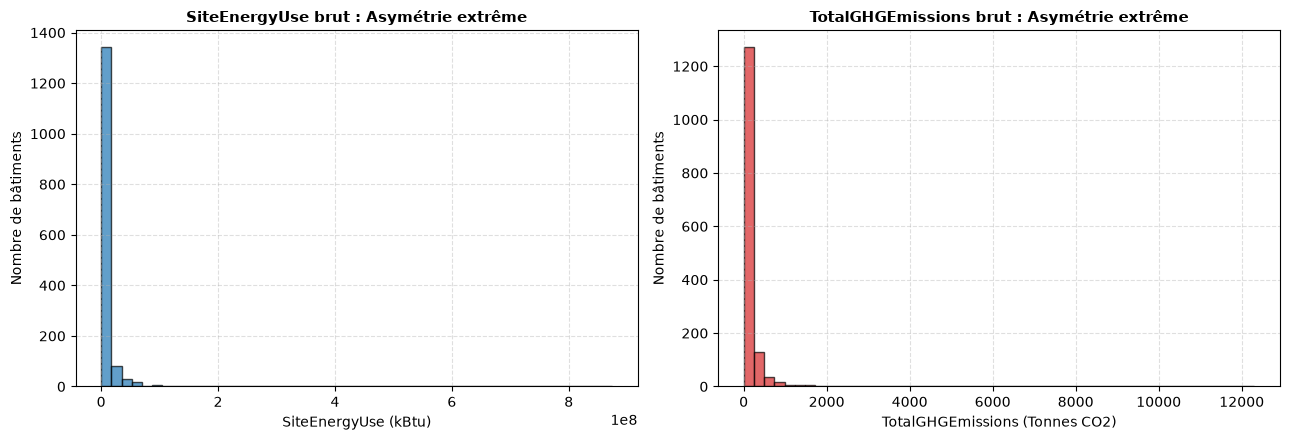

In [14]:
# Visualisation des variables

# Initialisation de la figure pour les distributions brutes
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Histogramme brut de la consommation d'énergie
axes[0].hist(df_non_residential_clean['SiteEnergyUse(kBtu)'], bins=50, color='#1f77b4', edgecolor='black', alpha=0.7)
axes[0].set_title("SiteEnergyUse brut : Asymétrie extrême", fontsize=11, fontweight='bold')
axes[0].set_xlabel("SiteEnergyUse (kBtu)")
axes[0].set_ylabel("Nombre de bâtiments")
axes[0].grid(True, linestyle='--', alpha=0.4)

# Histogramme brut des émissions de GES
axes[1].hist(df_non_residential_clean['TotalGHGEmissions'], bins=50, color='#d62728', edgecolor='black', alpha=0.7)
axes[1].set_title("TotalGHGEmissions brut : Asymétrie extrême", fontsize=11, fontweight='bold')
axes[1].set_xlabel("TotalGHGEmissions (Tonnes CO2)")
axes[1].set_ylabel("Nombre de bâtiments")
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [15]:
# La distribution est écrasée par quelques grosses valeurs qui concentrent l'essentiel de la variance
# On fait une transformation logarithmique (log(1+y) pour normaliser la forme et minimiser l'influence des erreurs sur les grosses valeurs des variables (erreur quadratique moyenne)
# Ainsi pendant l'entrainement automatique après le log chaque variable sera traitée avec la même importance peut importe sa valeur
# Calcul de asymétrie après transformation log(1 + y)
log_energy_asym = np.log1p(df_non_residential_clean['SiteEnergyUse(kBtu)']).skew().round(2)
log_ghg_asym = np.log1p(df_non_residential_clean['TotalGHGEmissions']).skew().round(2)

print(f"Asymétrie SiteEnergyUse(kBtu) : {19.33} -> après log1p : {log_energy_asym}")
print(f"Asymétrie TotalGHGEmissions   : {12.59} -> après log1p : {log_ghg_asym}")

Asymétrie SiteEnergyUse(kBtu) : 19.33 -> après log1p : 0.25
Asymétrie TotalGHGEmissions   : 12.59 -> après log1p : 0.18


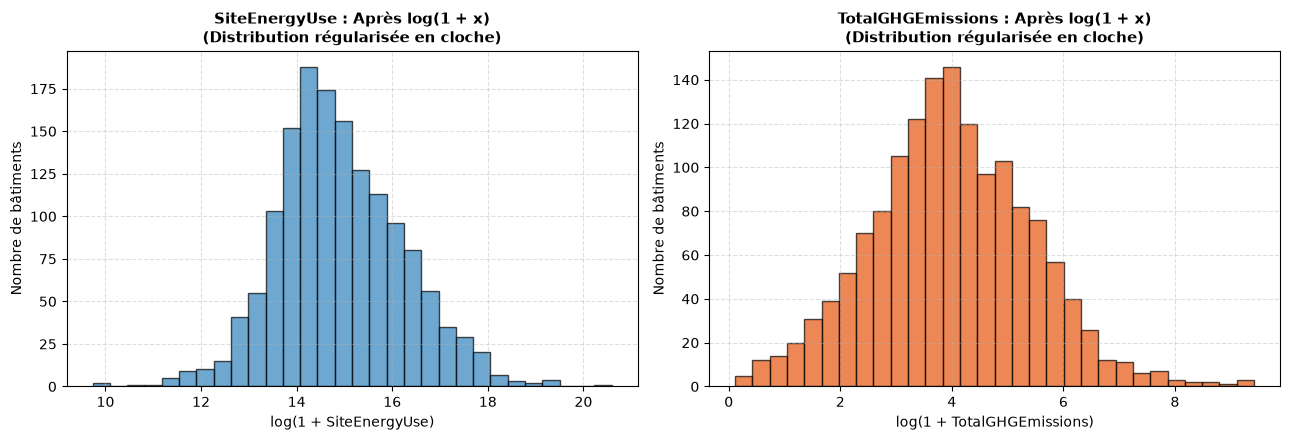

In [16]:
# Visualisation des variables avec application du log

# Transformation logarithmique des deux cibles
energy_log = np.log1p(df_non_residential_clean['SiteEnergyUse(kBtu)'])
ghg_log = np.log1p(df_non_residential_clean['TotalGHGEmissions'])

# Initialisation de la figure pour les distributions après log
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Histogramme après log de la consommation d'énergie
axes[0].hist(energy_log, bins=30, color='#3182bd', edgecolor='black', alpha=0.7)
axes[0].set_title("SiteEnergyUse : Après log(1 + x)\n(Distribution régularisée en cloche)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("log(1 + SiteEnergyUse)")
axes[0].set_ylabel("Nombre de bâtiments")
axes[0].grid(True, linestyle='--', alpha=0.4)

# Histogramme après log des émissions de GES
axes[1].hist(ghg_log, bins=30, color='#e6550d', edgecolor='black', alpha=0.7)
axes[1].set_title("TotalGHGEmissions : Après log(1 + x)\n(Distribution régularisée en cloche)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("log(1 + TotalGHGEmissions)")
axes[1].set_ylabel("Nombre de bâtiments")
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [17]:
# On intégre les données des log dans le dataset pour les conserver
df_non_residential_log = df_non_residential_clean.copy()

# Ajout des deux cibles transformées
df_non_residential_log['SiteEnergyUse_log'] = np.log1p(df_non_residential_log['SiteEnergyUse(kBtu)'])
df_non_residential_log['TotalGHGEmissions_log'] = np.log1p(df_non_residential_log['TotalGHGEmissions'])

<div style="border: 1px solid RGB(36,172,189);" >
<h3 style="margin: auto; padding: 20px; color: RGB(36,172,189); ">Nettoyage des colonnes avant entrainement</h3>
</div>

In [18]:
# On visualise le dataset et ses colonnes
df_non_residential_log.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity,SiteEnergyUse_log,TotalGHGEmissions_log
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,88434,0,88434,Hotel,Hotel,88434.0,NaN,NaN,NaN,NaN,NaN,60.0,81.699997,84.300003,182.500000,189.000000,7226362.5,7456910.0,2003882.00,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83,15.793246,5.525373
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,NaN,61.0,94.800003,97.900002,176.100006,179.399994,8387933.0,8664479.0,0.00,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86,15.942305,5.693261
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41,956110,196718,759392,Hotel,Hotel,756493.0,NaN,NaN,NaN,NaN,NaN,43.0,96.000000,97.699997,241.899994,244.100006,72587024.0,73937112.0,21566554.00,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19,18.100297,7.645053
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10,61320,0,61320,Hotel,Hotel,61320.0,NaN,NaN,NaN,NaN,NaN,56.0,110.800003,113.300003,216.199997,224.000000,6794584.0,6946800.5,2214446.25,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67,15.731637,5.660979
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18,175580,62000,113580,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,NaN,75.0,114.800003,118.699997,211.399994,215.600006,14172606.0,14656503.0,0.00,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88,16.466822,6.226556


In [19]:
df_non_residential_log.describe()

,OSEBuildingID,DataYear,ZipCode,CouncilDistrictCode,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseTypeGFA,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),Comments,TotalGHGEmissions,GHGEmissionsIntensity,SiteEnergyUse_log,TotalGHGEmissions_log
count,1485.000000,1485.0,1473.000000,1485.000000,1485.000000,1485.000000,1485.000000,1485.000000,1485.000000,1.485000e+03,1485.000000,1.485000e+03,1.481000e+03,719.000000,241.000000,1027.000000,1485.000000,1484.000000,1485.000000,1485.000000,1.485000e+03,1.484000e+03,1.485000e+03,1.485000e+03,1.485000e+03,1.485000e+03,1.485000e+03,0.0,1485.000000,1485.000000,1485.000000,1485.000000
mean,15941.906397,2016.0,98116.771894,4.332660,47.614965,-122.333171,1961.876768,1.185859,4.195960,1.207530e+05,12973.248485,1.077797e+05,1.026345e+05,36088.249370,11452.353528,65.776047,71.024512,73.392318,174.378855,176.426936,8.321387e+06,7.861282e+06,5.524537e+05,1.723816e+06,5.881659e+06,1.756844e+04,1.756844e+06,NaN,176.952141,1.555421,14.903819,3.982115
std,13676.987151,0.0,18.001196,2.208728,0.048692,0.024550,32.190183,3.099507,6.818398,3.089471e+05,43104.199701,2.958018e+05,2.897981e+05,65095.740278,27904.903737,28.211408,72.658737,73.597040,180.658993,180.592332,2.962525e+07,1.953123e+07,5.818374e+06,6.279846e+06,2.142684e+07,6.129597e+04,6.129597e+06,NaN,661.889792,2.180353,1.324265,1.441929
min,1.000000,2016.0,98006.000000,1.000000,47.499170,-122.411820,1900.000000,0.000000,0.000000,1.128500e+04,0.000000,1.128500e+04,7.583000e+03,0.000000,0.000000,1.000000,0.700000,0.000000,2.100000,0.000000,1.680890e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,NaN,0.120000,0.000000,9.729723,0.113329
25%,574.000000,2016.0,98105.000000,2.000000,47.582900,-122.343280,1930.000000,1.000000,1.000000,2.952500e+04,0.000000,2.858400e+04,2.626300e+04,4708.500000,1686.000000,49.000000,33.700001,35.400002,76.400002,79.099998,1.245924e+06,1.301256e+06,0.000000e+00,2.112968e+05,7.209450e+05,0.000000e+00,0.000000e+00,NaN,19.930000,0.350000,14.035389,3.041184
50%,21103.000000,2016.0,98109.000000,4.000000,47.611700,-122.333160,1965.000000,1.000000,2.000000,4.924900e+04,0.000000,4.741500e+04,4.544200e+04,10853.000000,5000.000000,73.000000,51.000000,53.400002,130.699997,133.500000,2.581742e+06,2.717591e+06,0.000000e+00,4.758666e+05,1.623657e+06,4.768320e+03,4.768320e+05,NaN,49.530000,0.850000,14.763975,3.922567
75%,24532.000000,2016.0,98125.000000,7.000000,47.648820,-122.322320,1988.000000,1.000000,4.000000,1.068600e+05,0.000000,9.630000e+04,9.447000e+04,32756.500000,10000.000000,89.000000,79.500000,82.925001,200.500000,202.699997,6.917280e+06,7.167893e+06,0.000000e+00,1.466880e+06,5.004995e+06,1.437252e+04,1.437252e+06,NaN,134.820000,1.810000,15.749533,4.911330
max,50224.000000,2016.0,98199.000000,7.000000,47.733870,-122.258640,2015.000000,111.000000,99.000000,9.320156e+06,512608.000000,9.320156e+06,9.320156e+06,441551.000000,303910.000000,100.000000,834.400024,834.400024,2620.000000,2620.000000,8.739237e+08,2.966717e+08,1.349435e+08,1.925775e+08,6.570744e+08,1.381912e+06,1.381912e+08,NaN,12307.160000,25.710000,20.588504,9.418018


In [20]:
# Vérification de présence d'incohérences
# Incohérence : sous-surfaces supérieures à la surface totale
incoherence_surface = (
    df_non_residential_log['PropertyGFABuilding(s)'] + df_non_residential_log['PropertyGFAParking']
) > (df_non_residential_log['PropertyGFATotal'] * 1.01)  # tolérance de 1% pour arrondis

print("Bâtiments avec sous-surfaces > surface totale :", incoherence_surface.sum())

# Surfaces <= 0
zero_gfa = df_non_residential_log['PropertyGFATotal'] <= 0
print("Bâtiments avec surface totale <= 0 :", zero_gfa.sum())

# Consommation d'énergie <= 0
zero_energy = df_non_residential_log['SiteEnergyUse(kBtu)'] <= 0
print("Bâtiments avec consommation <= 0 :", zero_energy.sum())

# Émissions de GES < 0 (certains bâtiments à énergie positive ou compensation affichent parfois des valeurs négatives)
neg_ghg = df_non_residential_log['TotalGHGEmissions'] < 0
print("Bâtiments avec émissions GES < 0 :", neg_ghg.sum())

# Années aberrantes (Seattle a été fondée au 18ème )
annee_incoherente = (
    (df_non_residential_log['YearBuilt'] > 2016) | 
    (df_non_residential_log['YearBuilt'] < 1800)
)
print("Bâtiments avec année de construction incohérente :", annee_incoherente.sum())

# Ratio surface par étage
surface_par_etage = df_non_residential_log['PropertyGFATotal'] / df_non_residential_log['NumberofFloors']

# Moins de 100 sq.ft (~9 m²) par étage pour un bâtiment non résidentiel
etage_microscopique = surface_par_etage < 100
print("Bâtiments avec surface par étage anormalement basse (< 100 sq.ft) :", etage_microscopique.sum())

# Somme des incohérences 
total_anomalies = (
    incoherence_surface.sum()
    + zero_gfa.sum()
    + zero_energy.sum()
    + neg_ghg.sum()
    + annee_incoherente.sum()
    + etage_microscopique.sum()
)

if total_anomalies == 0:
    print("\nVérification terminée : 0 incohérence détectée. Le jeu de données est cohérent")
else:
    print(f"Attention : {total_anomalies} bâtiments avec des données incohérentes détectés.")

Bâtiments avec sous-surfaces > surface totale : 0
Bâtiments avec surface totale <= 0 : 0
Bâtiments avec consommation <= 0 : 0
Bâtiments avec émissions GES < 0 : 0
Bâtiments avec année de construction incohérente : 0
Bâtiments avec surface par étage anormalement basse (< 100 sq.ft) : 0

Vérification terminée : 0 incohérence détectée. Le jeu de données est cohérent


In [21]:
# Taux de valeurs manquantes par colonne, trié par ordre décroissant
missing_summary = pd.DataFrame({
    'NaN_count': df_non_residential_log.isna().sum(),
    'NaN_pct': (df_non_residential_log.isna().mean() * 100).round(2)
})

# Affichage des colonnes qui ont au moins 1 valeur manquante
missing_summary[missing_summary['NaN_count'] > 0].sort_values(by='NaN_count', ascending=False)

,NaN_count,NaN_pct
Comments,1485,100.00
Outlier,1469,98.92
YearsENERGYSTARCertified,1390,93.60
ThirdLargestPropertyUseType,1244,83.77
ThirdLargestPropertyUseTypeGFA,1244,83.77
SecondLargestPropertyUseTypeGFA,766,51.58
SecondLargestPropertyUseType,766,51.58
ENERGYSTARScore,458,30.84
ZipCode,12,0.81
LargestPropertyUseType,4,0.27


In [22]:
print(f"Dimensions du dataset df_non_residential_log : {df_non_residential_log.shape}")

Dimensions du dataset df_non_residential_log : (1485, 48)


In [23]:
# On remarque des étages à 0, verification des lignes
df_zero_floors = df_non_residential_log[df_non_residential_log['NumberofFloors'] == 0]

print(f"Nombre de bâtiments concernés : {len(df_zero_floors)}")
df_zero_floors

Nombre de bâtiments concernés : 11


,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity,SiteEnergyUse_log,TotalGHGEmissions_log
166,267,2016,NonResidential,Hotel,Grand Hyatt Seattle,721 Pine St,Seattle,WA,98101.0,6792120000,7,DOWNTOWN,47.61275,-122.33330,1999,1.0,0,934292,0,934292,"Hotel, Other, Parking, Restaurant, Retail Store",Hotel,495536.0,Parking,438756.0,Restaurant,49700.0,NaN,NaN,117.900002,120.500000,272.899994,278.200012,6.504728e+07,66502836.0,0.0,1.153696e+07,39364114.0,256831.625000,25683162.0,False,NaN,Compliant,NaN,1638.46,1.75,17.990625,7.402122
487,656,2016,NonResidential,Medical Office,Arnold Pavilion,1221 Madison Street,Seattle,WA,98104.0,8725990000,3,EAST,47.60979,-122.32298,2004,1.0,0,225982,0,225982,Medical Office,Medical Office,200184.0,NaN,NaN,NaN,NaN,NaN,53.0,102.699997,103.699997,246.899994,245.300003,2.056062e+07,20764814.0,7815663.0,3.735333e+06,12744957.0,0.000000,0.0,False,NaN,Compliant,NaN,692.12,3.06,16.838888,6.541203
564,758,2016,NonResidential,Other,Pacific Place,600 Pine Street,Seattle,WA,98101.0,6600470000,7,DOWNTOWN,47.61289,-122.33531,1999,1.0,0,947987,0,947987,"Office, Other - Entertainment/Public Assembly,...",Other - Mall,561684.0,Other - Entertainment/Public Assembly,100000.0,Restaurant,80000.0,NaN,NaN,62.299999,62.099998,195.600006,194.899994,4.651096e+07,46343304.0,0.0,1.363158e+07,46510954.0,0.000000,0.0,False,NaN,Compliant,NaN,324.25,0.34,17.655199,5.784594
1754,23311,2016,NonResidential,Medical Office,HART First Hill LLC,1124 Columbia Street,Seattle,WA,98104.0,8590900646,3,EAST,47.60862,-122.32372,1945,1.0,0,274568,0,274568,"Medical Office, Parking",Medical Office,228133.0,Parking,135954.0,NaN,NaN,NaN,52.0,111.000000,111.199997,235.500000,233.100006,2.531153e+07,25358122.0,13296249.0,3.521476e+06,12015275.0,0.000000,0.0,False,NaN,Compliant,NaN,1110.07,4.04,17.046770,7.013079
1993,24086,2016,Campus,Other,(ID#24086)Campus1:KC Metro Transit Atlantic Ce...,1333 AIRPORT WAY S,Seattle,WA,98134.0,7666203387,2,GREATER DUWAMISH,47.59042,-122.32498,1991,10.0,0,230971,0,230971,"Other, Parking",Other,230970.0,Parking,0.0,NaN,NaN,NaN,NaN,91.000000,96.199997,235.100006,242.199997,2.102229e+07,22230844.0,0.0,4.519276e+06,15419770.0,56025.152340,5602515.0,False,NaN,Compliant,NaN,405.05,1.75,16.861094,6.006476
3130,40028,2016,NonResidential,Warehouse,Sandpoint #5,7561 63rd Ave NE,Seattle,WA,98115.0,0225049077,4,NORTHEAST,47.68454,-122.26235,1940,1.0,0,384772,0,384772,"Non-Refrigerated Warehouse, Office",Non-Refrigerated Warehouse,349953.0,Office,63872.0,NaN,NaN,NaN,69.0,36.700001,39.000000,84.099998,86.500000,1.520676e+07,16139557.0,0.0,2.642108e+06,9014872.0,61918.878910,6191888.0,False,NaN,Compliant,NaN,391.70,1.02,16.537251,5.973046
3131,40031,2016,NonResidential,Medical Office,Sandpoint #25,6222 NE 74th St,Seattle,WA,98115.0,0225049077,4,NORTHEAST,47.68240,-122.26223,1960,1.0,0,30287,0,30287,Medical Office,Medical Office,28050.0,NaN,NaN,NaN,NaN,NaN,32.0,78.199997,81.300003,217.399994,220.600006,2.193115e+06,2279632.5,0.0,5.320647e+05,1815405.0,3777.100342,377710.0,False,NaN,Compliant,NaN,32.72,1.08,14.600834,3.518091
3132,40034,2016,NonResidential,Small- and Mid-Sized Office,Sandpoint #29,6200 NE 74th ST,Seattle,WA,98115.0,0225049077,4,NORTHEAST,47.68254,-122.26299,1960,1.0,0,21931,0,219

In [24]:
# Au vu du nombre et des batiements il s'agit d'une erreur on corrige les 0 en 1
df_non_residential_log['NumberofFloors'] = df_non_residential_log['NumberofFloors'].apply(lambda x: 1 if x == 0 else x)

In [25]:
print("Modalités PrimaryPropertyType :", df_non_residential_log['PrimaryPropertyType'].nunique())
print("Modalités LargestPropertyUseType :", df_non_residential_log['LargestPropertyUseType'].nunique())

Modalités PrimaryPropertyType : 18
Modalités LargestPropertyUseType : 50


In [26]:
# On identifie les energies utilisées qui influenceront les émissions et la consommation d'energie
# Utilisation de gaz (1 si > 0, sinon 0)
df_non_residential_log['HasGas'] = (df_non_residential_log['NaturalGas(kBtu)'] > 0).astype(int)

# Utilisation de la vapeur  (1 si > 0, sinon 0)
df_non_residential_log['HasSteam'] = (df_non_residential_log['SteamUse(kBtu)'] > 0).astype(int)

In [27]:
# On va créer un dataset selectionné qui ne contiendra que les colonnes qui peuvent corréler la consommation
# On ne conservera donc pas les colonnes avec plus de 50% de Nan (qui ne semble pas utiles), les identifiants artificiels (id), les consommations partielles (que electricité par ex)
# Définition explicite des colonnes à conserver : 
colonnes_selectionees = [
    # Type et usage
    'PrimaryPropertyType', # LargestPropertyUseType aurait été intéressante et plus détaillée mais est déclarative -> donc pas dispo si pas d'enquete et peut être trop détaillée
    'Neighborhood',
    
    # Caractéristiques
    'YearBuilt',
    'NumberofBuildings',
    'NumberofFloors',
    'PropertyGFATotal',
    'PropertyGFABuilding(s)',
    'PropertyGFAParking',

    # Type d'energie utilisée
    'HasGas',
    'HasSteam',
       
    # Target en log (on garde les brutes pour les garder à dispo)
    'SiteEnergyUse(kBtu)',
    'SiteEnergyUse_log',
    'TotalGHGEmissions',
    'TotalGHGEmissions_log'
]

# Nouveau DataFrame dédié à l'analyse
df_colonnes_selectionees = df_non_residential_log[colonnes_selectionees].copy()

print(f"Dimensions du nouveau dataset : {df_colonnes_selectionees.shape}")
df_colonnes_selectionees.head(3)

Dimensions du nouveau dataset : (1485, 14)


,PrimaryPropertyType,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFABuilding(s),PropertyGFAParking,HasGas,HasSteam,SiteEnergyUse(kBtu),SiteEnergyUse_log,TotalGHGEmissions,TotalGHGEmissions_log
0,Hotel,DOWNTOWN,1927,1.0,12,88434,88434,0,1,1,7226362.5,15.793246,249.98,5.525373
1,Hotel,DOWNTOWN,1996,1.0,11,103566,88502,15064,1,0,8387933.0,15.942305,295.86,5.693261
2,Hotel,DOWNTOWN,1969,1.0,41,956110,759392,196718,1,1,72587024.0,18.100297,2089.28,7.645053


<div style="border: 1px solid RGB(36,172,189);" >
<h3 style="margin: auto; padding: 20px; color: RGB(36,172,189); ">Vérification des corrélations</h3>
</div>

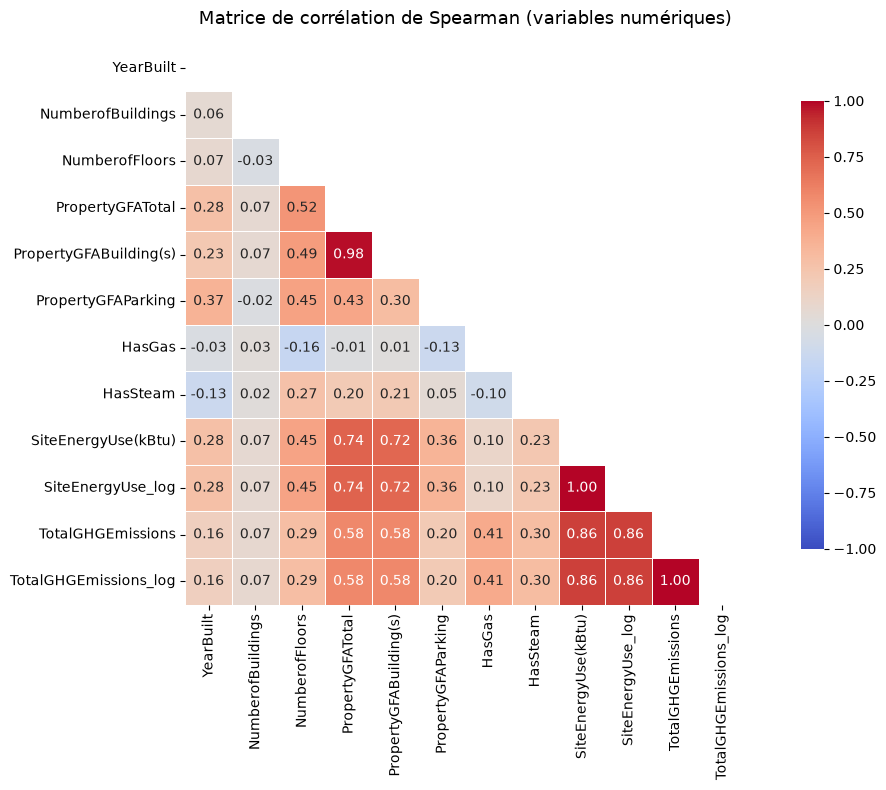

In [28]:
# On conserve uniquement les colonnes numériques, on regardera les colonnes textuelles après
num_cols = df_colonnes_selectionees.select_dtypes(include=['int64', 'float64']).columns

# Calcul de la matrice de corrélation de Spearman (on met spearman plutôt que pearson a cause des outliers)
corr = df_colonnes_selectionees[num_cols].corr(method='spearman')

# Masque pour masquer le triangle supérieur
mask = np.triu(np.ones_like(corr, dtype=bool))

# Tracé du demi-heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title("Matrice de corrélation de Spearman (variables numériques)", fontsize=13, pad=15)
plt.tight_layout()

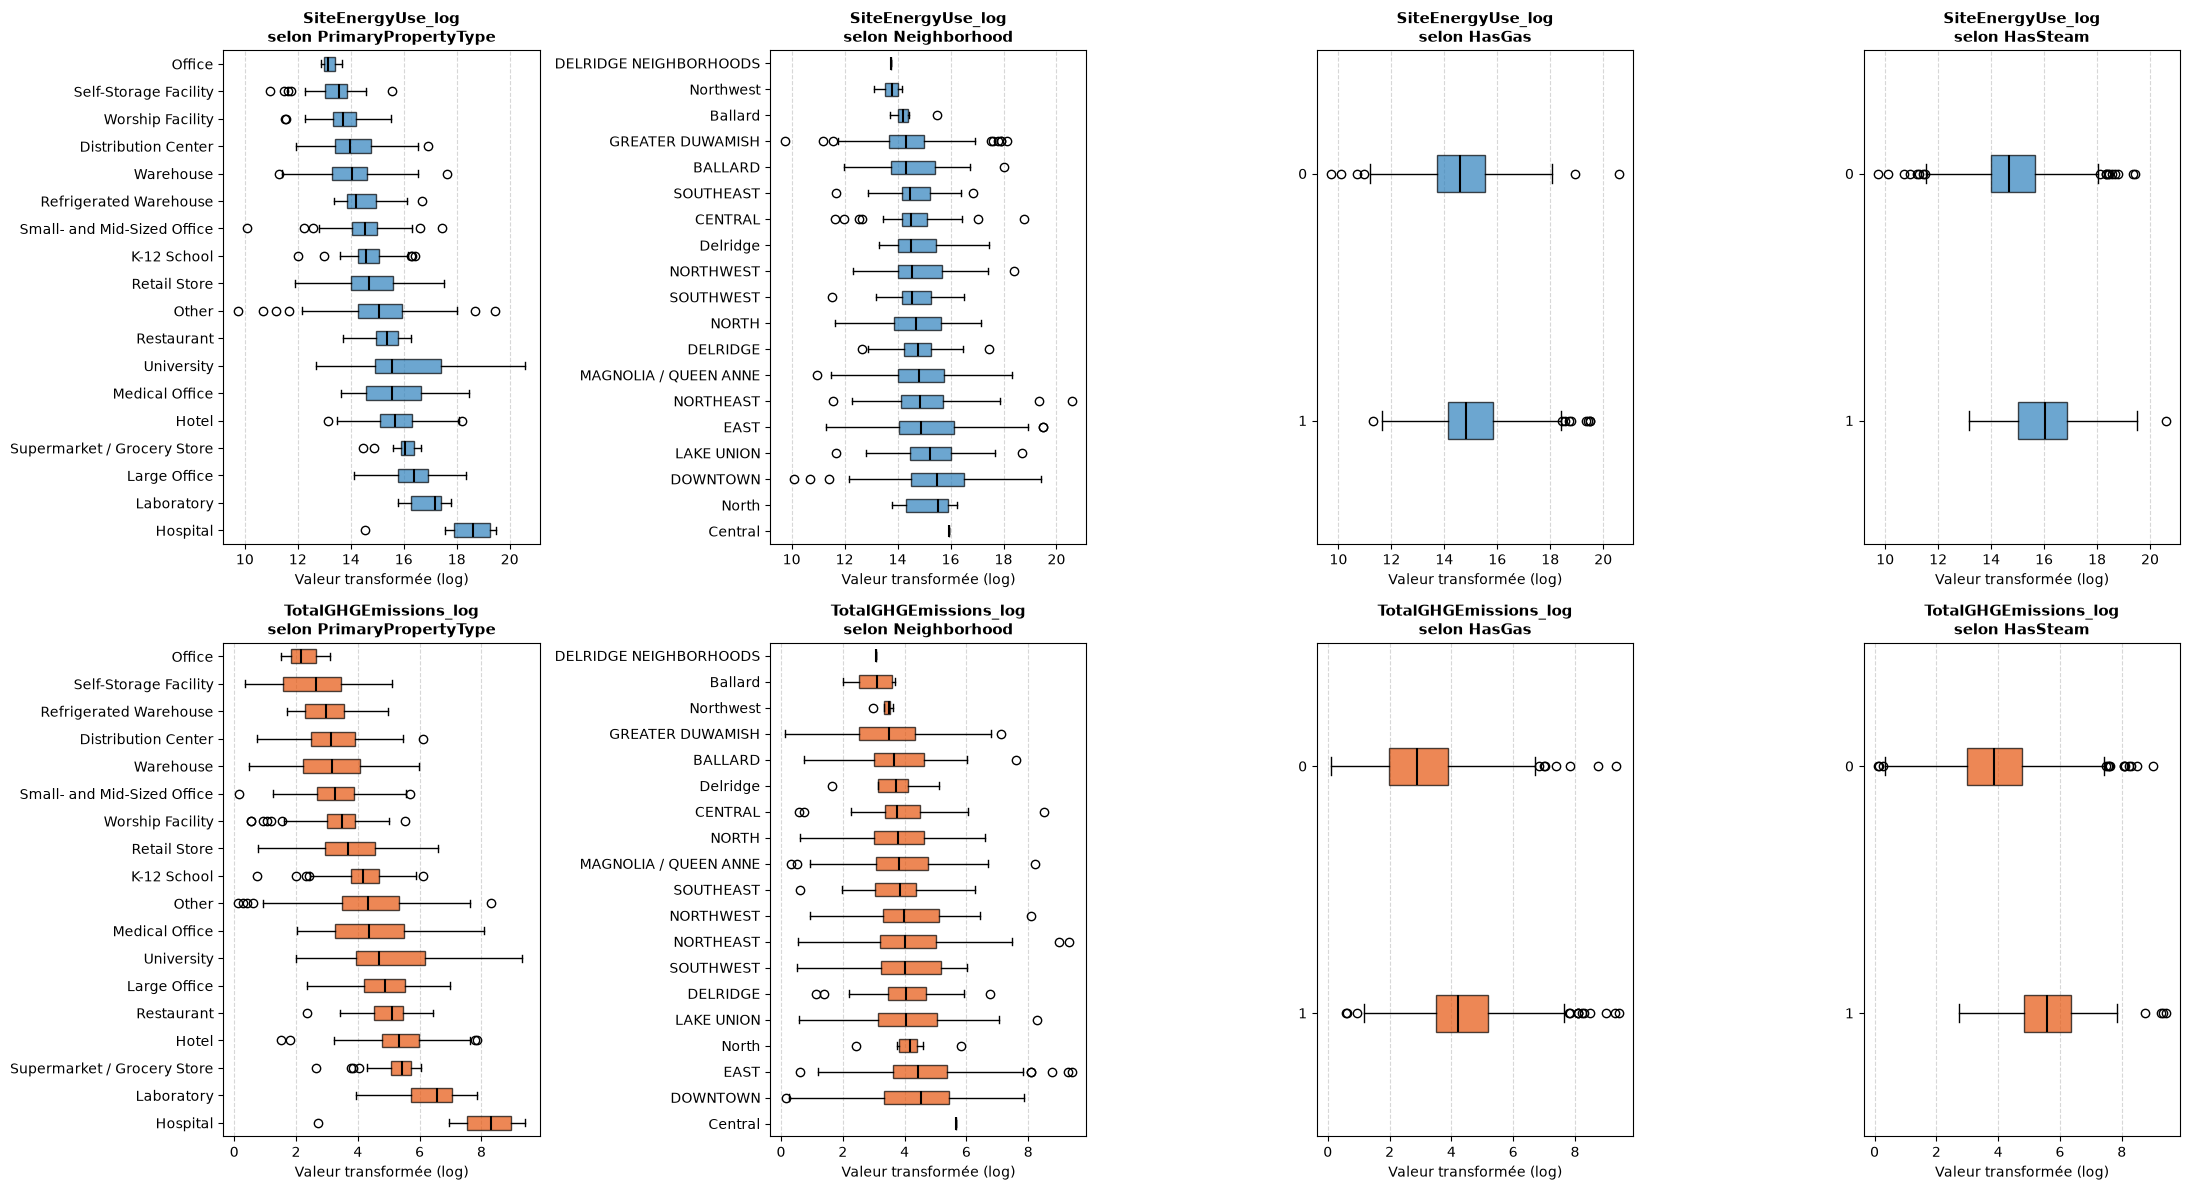

In [29]:
# On regarde maintenant les variables qualitatives
fig, axes = plt.subplots(2, 4, figsize=(22, 12))

categorical_vars = ['PrimaryPropertyType', 'Neighborhood', 'HasGas', 'HasSteam']
targets = ['SiteEnergyUse_log', 'TotalGHGEmissions_log']

for row_idx, target in enumerate(targets):
    for col_idx, cat in enumerate(categorical_vars):
        ax = axes[row_idx, col_idx]
        
        # Tri des catégories par médiane décroissante
        order = (
            df_colonnes_selectionees.groupby(cat)[target]
            .median()
            .sort_values(ascending=False)
            .index.tolist()
        )
        
        # Préparation des séries de données ordonnées
        data_to_plot = [
            df_colonnes_selectionees.loc[df_colonnes_selectionees[cat] == val, target].dropna().values
            for val in order
        ]
        
        # Tracé natif avec Matplotlib (aucun conflit de version ou de positions)
        color_box = "#2e81bd" if row_idx == 0 else '#e6550d'
        
        # Boxplot avec la syntaxe moderne Matplotlib
        bp = ax.boxplot(
            data_to_plot,
            orientation='horizontal',
            patch_artist=True,
            tick_labels=[str(v) for v in order],
            boxprops=dict(facecolor=color_box, alpha=0.7, edgecolor='black'),
            medianprops=dict(color='black', linewidth=1.5)
        )
        
        ax.set_title(f"{target}\nselon {cat}", fontsize=11, fontweight='bold')
        ax.set_xlabel("Valeur transformée (log)")
        ax.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [30]:
# On va créer un dataset qui ne contiendra que les colonnes qui semblent corrélées à la consommation d'energie ou les émissions
# On se base sur les colonnes avec corrélations observées quantitatives et qualitatives
# Définition explicite des colonnes à conserver : 
colonnes_conservees = [
    # Type et usage
    'PrimaryPropertyType',
    'Neighborhood', # semble moins impactante mais affinera la fiabilité des prédictions
    
    # Caractéristiques
    'YearBuilt', # peu impactante mais à transformer en âge, sans doute à affiner
    'NumberofFloors',
    'PropertyGFATotal', # est conservé au détriment de 'PropertyGFABuilding(s)' avec une corrélation de 0.98 entre les 2
    'PropertyGFAParking',

    # Type d'energie utilisée
    'HasGas',
    'HasSteam',
    
    # Target en log (on garde les brutes pour les garder à dispo)
    'SiteEnergyUse(kBtu)',
    'SiteEnergyUse_log',
    'TotalGHGEmissions',
    'TotalGHGEmissions_log'
]

# Nouveau DataFrame dédié à la modélisation
df_colonnes_conservees = df_colonnes_selectionees[colonnes_conservees].copy()

print(f"Dimensions du nouveau dataset : {df_colonnes_conservees.shape}")
df_colonnes_conservees.head(3)

Dimensions du nouveau dataset : (1485, 12)


,PrimaryPropertyType,Neighborhood,YearBuilt,NumberofFloors,PropertyGFATotal,PropertyGFAParking,HasGas,HasSteam,SiteEnergyUse(kBtu),SiteEnergyUse_log,TotalGHGEmissions,TotalGHGEmissions_log
0,Hotel,DOWNTOWN,1927,12,88434,0,1,1,7226362.5,15.793246,249.98,5.525373
1,Hotel,DOWNTOWN,1996,11,103566,15064,1,0,8387933.0,15.942305,295.86,5.693261
2,Hotel,DOWNTOWN,1969,41,956110,196718,1,1,72587024.0,18.100297,2089.28,7.645053


# Modélisation 

### Import des modules 

In [31]:
#Selection
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV, 
    cross_validate,
    cross_val_predict,
    KFold,
)
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error 
from sklearn.inspection import permutation_importance

#Preprocess
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

#Modèles
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
import lightgbm as lgb

#Pipepline (pour faire le fit et le transform sur le jeu de train et de test sans fuite de données)
from sklearn.pipeline import Pipeline


### Analyse des modèles proposés à l'import

Dummy : Niveau zéro de performance, ne fait qu'une moyenne de la cible, les autres algo doivent être plus performants

Linear Regression : cherche une relation linéaire avec un coefficient de droite sur des variables continues 

Ridge : Régression linéaire régularisée, force les coefficients à se rapprocher de zéro sans jamais s'annuler

SVR : Support Vector Regressor, cherche une relation courbe avec une tolérence face aux erreurs si on reste proche de la courbe

Random Forest Regressor (Forêt aléatoire) : Il génère un grand nombre d'arbres de décision indépendants de manière parallèle et fait la moyenne de leurs prédictions, Arbres profonds

Gradient Boosting Regressor (Forêt séquentielle) :  Crée les arbres les uns après les autres (en série). Chaque nouvel arbre apprend des faiblesses de ses prédécesseurs en ré-évaluant avec toutes les lignes des données à chaque fois.

LightGBM (Light Gradient-Boosting Machine) : Crée ses arbres comme Gradient Boosting mais réévalue avec uniquement avec 100% des lignes avec des grosses erreurs et juste quelques lignes parmi les autres. Sans doute plus adapté quand les données sont très volumineuses et hétérogènes (lié à la réduction des lignes entre chaque arbre ?)


<div style="border: 1px solid RGB(36,172,189);" >
<h3 style="margin: auto; padding: 20px; color: RGB(36,172,189); ">Feature Engineering</h3>
</div>

A réaliser : Enrichir le jeu de données actuel avec de nouvelles features issues de celles existantes. 

En règle générale : On utilise la méthode .apply() de Pandas pour créer une nouvelle colonne à partir d'une colonne existante. N'hésitez pas à regarder les exemples dans les chapitres de cours donnés en ressource

In [32]:
# On commence par créer les variables identifiées : Année -> age, Nombre d'étages -> surface par étage, Surfaces en log comme pour les emissions et l'energie (gestion des géants)

# Copie du dataset avant modification des valeurs
df_features = df_colonnes_conservees.copy()

# Age des batiments
df_features['BuildingAge'] = 2016 - df_features['YearBuilt']

# Passage en log1p des surfaces (total et parking))
df_features['PropertyGFATotal_log'] = np.log1p(df_features['PropertyGFATotal'])
df_features['PropertyGFAParking_log'] = np.log1p(df_features['PropertyGFAParking'])

# Suppression des colonnes brutes, redondantes
cols_to_drop = [
    'YearBuilt',
    'PropertyGFAParking',       # remplacé par PropertyGFAParking_log
    'PropertyGFATotal',         # remplacé par PropertyGFATotal_log
]

# On filtre uniquement sur les colonnes réellement présentes dans df_features
df_features.drop(columns=[c for c in cols_to_drop if c in df_features.columns], inplace=True)

print(f"Dimensions finales de df_features : {df_features.shape}")
print("\nListe des colonnes prêtes pour la modélisation :")
print(df_features.dtypes)

Dimensions finales de df_features : (1485, 12)

Liste des colonnes prêtes pour la modélisation :
PrimaryPropertyType        object
Neighborhood               object
NumberofFloors              int64
HasGas                      int64
HasSteam                    int64
SiteEnergyUse(kBtu)       float64
SiteEnergyUse_log         float64
TotalGHGEmissions         float64
TotalGHGEmissions_log     float64
BuildingAge                 int64
PropertyGFATotal_log      float64
PropertyGFAParking_log    float64
dtype: object


In [33]:
df_features.head()

,PrimaryPropertyType,Neighborhood,NumberofFloors,HasGas,HasSteam,SiteEnergyUse(kBtu),SiteEnergyUse_log,TotalGHGEmissions,TotalGHGEmissions_log,BuildingAge,PropertyGFATotal_log,PropertyGFAParking_log
0,Hotel,DOWNTOWN,12,1,1,7226362.5,15.793246,249.98,5.525373,89,11.390023,0.000000
1,Hotel,DOWNTOWN,11,1,0,8387933.0,15.942305,295.86,5.693261,20,11.547974,9.620129
2,Hotel,DOWNTOWN,41,1,1,72587024.0,18.100297,2089.28,7.645053,47,13.770629,12.189532
3,Hotel,DOWNTOWN,10,1,1,6794584.0,15.731637,286.43,5.660979,90,11.023878,0.000000
4,Hotel,DOWNTOWN,18,1,0,14172606.0,16.466822,505.01,6.226556,36,12.075856,11.034906


<div style="border: 1px solid RGB(36,172,189);" >
<h3 style="margin: auto; padding: 20px; color: RGB(36,172,189); ">Préparation des features pour la modélisation + Découpage Train - Test</h3>
</div>

A réaliser :
* Si ce n'est pas déjà fait, supprimer toutes les colonnes peu pertinentes pour la modélisation.
* Tracer la distribution de la cible pour vous familiariser avec l'ordre de grandeur. En cas d'outliers, mettez en place une démarche pour les supprimer.
* Débarrassez-vous des features redondantes en utilisant une matrice de corrélation de Pearson. Pour cela, utiisez la méthode corr() de Pandas, couplé d'un graphique Heatmap de la librairie Seaborn 
* Réalisez différents graphiques pour comprendre le lien entre vos features et la target (boxplots, scatterplots, pairplot si votre nombre de features numériques n'est pas très élevé).
*  Séparez votre jeu de données en un Pandas DataFrame X (ensemble de feautures) et Pandas Series y (votre target).
* Si vous avez des features catégorielles, il faut les encoder pour que votre modèle fonctionne. Les deux méthodes d'encodage à connaitre sont le OneHotEncoder et le LabelEncoder

In [34]:
# Supprimer colonnes peu pertinentes -> Fait
# Distribution cible et outliers -> Fait et cibles passées en log(1+x)
# Features redondantes (Pearson) -> fait avec Spearman dû à la présence d'outliers
# Graphiques lien features/target -> Fait heatmap pour les quantitatives et boxplot pour les qualitatives
# Séparer en X (DataFrame) et y (Series) -> à faire
# Encoder les features catégorielles -> à faire

In [35]:
# Séparer en X (DataFrame) et y (Series)
# On conserve 2 cibles (energy et emissions) selon l'objectif de les estimer d'autant plus que leurs corrélations sont différentes

# Copie du dataset
df_model = df_features.copy()

# Liste des colonnes cibles (brutes et log) à exclure des variables explicatives
target_cols = [
    'SiteEnergyUse(kBtu)', 
    'SiteEnergyUse_log', 
    'TotalGHGEmissions', 
    'TotalGHGEmissions_log'
]

# Séparation de la matrice explicative X et des deux vecteurs cibles y
X = df_model.drop(columns=[c for c in target_cols if c in df_model.columns])
y_energy = df_model['SiteEnergyUse_log'].copy()
y_ghg = df_model['TotalGHGEmissions_log'].copy()

# Découpage (80 % train / 20 % test) pour l'energy
X_train, X_test, y_train_energy, y_test_energy = train_test_split(
    X, y_energy, test_size=0.20, random_state=42
)

# Découpage (80 % train / 20 % test) pour les GHG : _, _, ne seront pas conservées, on garde X_train, X_test comme base commune d'entraiement
_, _, y_train_ghg, y_test_ghg = train_test_split(
    X, y_ghg, test_size=0.20, random_state=42
)

print(f"X_train : {X_train.shape} | X_test : {X_test.shape}")
print(f"y_train_energy : {y_train_energy.shape} | y_test_energy : {y_test_energy.shape}")
print(f"y_train_ghg    : {y_train_ghg.shape} | y_test_ghg    : {y_test_ghg.shape}")

X_train : (1188, 8) | X_test : (297, 8)
y_train_energy : (1188,) | y_test_energy : (297,)
y_train_ghg    : (1188,) | y_test_ghg    : (297,)


In [36]:
# Encoder les features catégorielles : OneHotEncoder ou LabelEncoder (proposés)
# LabelEncoder est conçu pour encoder la variable cible qualitative donc inadapté : attribut un entier à chaque catégorie, ce qui sera perçu comme une hierarchie par un modele linéaire (ce qui peut être le cas mais pas içi)
# OneHotEncoder crée une colonne binaire (0 ou 1) par modalité distincte, un bureau devient $[1, 0, 0]$, un hôtel $[0, 1, 0]$, etc... donc pas de hierarche et compatible tout modèle

# On fait l'encodage après le découpage pour éviter le data leakage et ne pas mettre à disposition des données de test au train
# StandardScaler -> aurait pu faire une fuite par ses calculs de moyenne et ecart type
# OneHotEncoder -> aurait pu faire une fuite par connaissance des colonnes de catégorie

# On évite une fuite de données on va faire un apprentissage (fit) sur uniquement sur 80% du train et on met de côté 20% du train pour tester des données inconnues

# Définition des familles de colonnes
cat_cols = ['PrimaryPropertyType', 'Neighborhood']
binary_cols = ['HasGas', 'HasSteam']
num_cols = [col for col in X_train.columns if col not in cat_cols + binary_cols]

# Le pipeline d'assemblage
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
        ('bin', 'passthrough', binary_cols)
    ],
    verbose_feature_names_out=False # Enleve les informations de l'execution des transformers (temps d'execution, poids...)
)

# Inspection visuelle : transformation d'un échantillon pour visualisation de l'effet des encodages
sample_transformed = preprocessor.fit_transform(X_train.head(5))
sample_feature_names = preprocessor.get_feature_names_out()

df_sample_check = pd.DataFrame(sample_transformed, columns=sample_feature_names)
print(f"Structure après encodage : {df_sample_check.shape[1]} colonnes générées.")
df_sample_check.head(3)

Structure après encodage : 15 colonnes générées.


,NumberofFloors,BuildingAge,PropertyGFATotal_log,PropertyGFAParking_log,PrimaryPropertyType_Distribution Center,PrimaryPropertyType_K-12 School,PrimaryPropertyType_Other,PrimaryPropertyType_Small- and Mid-Sized Office,PrimaryPropertyType_Warehouse,Neighborhood_DOWNTOWN,Neighborhood_GREATER DUWAMISH,Neighborhood_NORTHWEST,Neighborhood_SOUTHWEST,HasGas,HasSteam
0,-0.323498,0.096499,-0.829073,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1,-0.862662,-0.868488,1.806074,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,0.215666,-0.649173,-1.024501,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0


On regarde les possibilités de validations croiées dont le but est de s'assurer d'utiliser toutes les données du dataset initial pour entrainer et tester le modèle :

Validation croisée K-folds : On découpe le dataset en x partie, il y aura donc x entrainements et chacune des x parties qui sera testé le reste étant pour l'entrainement
Pour mesurer la performance on fait la moyenne des résultats des x test (accurracy par exemple)
Inconvéniant : si le dataset a des catégories à prédire différentes il peut prendre il peut y avoir des biais d'apprentissage selon la catégorie contenue dans x 

Validation croisée Stratified K-folds : Même principe de test en x partie sauf que les parties x de test prennent à chaque fois une partie de chaque catégorie pour être representatif
A utiliser lorsque la cible est catégoricielle et non numérique continue

Validation croisée Leave one out : dans les très petits dataset car le test se fait avec chaque observation du dataset (ex : 1 test 99 entrainements) - très peu utilisé 

Validation croisée Leave p out : dans les très petits dataset car le test se fait avec p = x ou x représente le nombre d'observation prises en test de manière aléatoire, il faut donc itérer



<div style="border: 1px solid RGB(36,172,189);" >
<h3 style="margin: auto; padding: 20px; color: RGB(36,172,189); ">Comparaison de différents modèles supervisés</h3>
</div>

A réaliser :
* Pour chaque algorithme que vous allez tester, vous devez :
    * Réaliser au préalable une séparation en jeu d'apprentissage et jeu de test via une validation croisée.
    * Si les features quantitatives que vous souhaitez utiliser ont des ordres de grandeur très différents les uns des autres, et que vous utilisez un algorithme de regression qui est sensible à cette différence, alors il faut réaliser un scaling (normalisation) de la donnée au préalable. -> un StandardScaler a déjà été appliqué dans ColumnTransformer
    * Entrainer le modèle sur le jeu de Train
    * Prédire la cible sur la donnée de test (nous appelons cette étape, l'inférence).
    * Calculer les métriques de performance R2, MAE et RMSE sur le jeu de train et de test.
    * Interpréter les résultats pour juger de la fiabilité de l'algorithme.
* Vous pouvez choisir par exemple de tester un modèle linéaire, un modèle à base d'arbres et un modèle de type SVM
* Déterminer le modèle le plus performant parmi ceux testés.

3 étapes :

Etape 1 : Comparer les différents algorithmes avec cross_val_predict plutôt que cross_validate (ou cross_val_score, encore moins complet) pour tester la performance des modèles possibles

Etape 2 : Auditer le modèle vainqueur avec cross_val_predict pour analyser la présence d'erreurs
    cross_validate renvoie un score de performance
    cross_val_predict renvoie les prédictions pour chaque ligne des données

Etape 3 : Execution finale sur le jeu de test (X_test)


In [37]:
# Etape 1 : Comparer les différents algorithmes avec cross_validate (+ cross_val_predict pour la MAE réelle) SUR ENERGY
# La validation croisée K-folds classique est selectionnée au vu de la variable numérique continue des cibles (emissions et energie) :

# Sélection des modèles proposés + Gradient Boosting + amélioration des hyperparamètres 
models_energy = {
    'Dummy (Moyenne)': DummyRegressor(strategy='mean'),
    'Linear Regression': LinearRegression(),
    'Ridge (Linéaire régularisé)': Ridge(alpha=1.0),
    'SVR Support Vector Regressor': SVR(C=1.0, epsilon=0.1),
    'Random Forest (Arbres)': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=42),
    'LightGBM (Calibré)': lgb.LGBMRegressor(n_estimators=300, learning_rate=0.032, max_depth=4, subsample=0.76, random_state=42, num_leaves=16, min_child_samples=4, subsample_freq=1, verbose=-1, n_jobs=-1)
}

# Découpage K-Fold pour la validation croisée (5 plis stratifiés aléatoirement)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Métriques statistiques calculées pli par pli via cross_validate
scoring_metrics = {
    'r2': 'r2',
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error'
}

# Cible réelle non logarithmique pour l'interprétation décideur en MAE réelle (kBtu)
y_train_energy_real = np.expm1(y_train_energy)

results_energy = []

# Comparatif des modèles avec étanchéité Pipeline anti-fuite
for name, model in models_energy.items():
    # Assemblage hermétique : le préprocessing (scaling, one-hot) est fitté
    # exclusivement sur les 80 % d'apprentissage à chaque pli
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])
    
    # Evaluation statistique : diagnostic d'overfitting (train vs val) et stabilité inter-folds
    cv_res = cross_validate(
        pipe,
        X_train,
        y_train_energy,
        cv=cv,
        scoring=scoring_metrics,
        return_train_score=True,
        n_jobs=-1
    )
    
    # Prédictions cross_val_predict hors-échantillon (out-of-fold) pour le calcul de la métrique terrain et passage en exponentielle pour le MAE log pour avoir des données réelles
    y_pred_log = cross_val_predict(pipe, X_train, y_train_energy, cv=cv, n_jobs=-1)
    y_pred_real = np.clip(np.expm1(y_pred_log), 0, None)
    
    # Agrégation des métriques statistiques et décideur
    results_energy.append({
        'Modèle': name,
        'R² Train': cv_res['train_r2'].mean(),
        'R² Val (mean)': cv_res['test_r2'].mean(),
        'R² Val (std)': cv_res['test_r2'].std(),
        'Écart Train - Val': cv_res['train_r2'].mean() - cv_res['test_r2'].mean(),
        'MAE Val (log)': -cv_res['test_mae'].mean(),
        'RMSE Val (log)': -cv_res['test_rmse'].mean(),
        'MAE Réelle (kBtu)': mean_absolute_error(y_train_energy_real, y_pred_real)
    })

# Synthèse ordonnée par l'erreur absolue moyenne de validation (log)
df_comparison_energy = pd.DataFrame(results_energy).sort_values(by='MAE Val (log)', ascending=True)
df_comparison_energy.round(3)

,Modèle,R² Train,R² Val (mean),R² Val (std),Écart Train - Val,MAE Val (log),RMSE Val (log),MAE Réelle (kBtu)
6,LightGBM (Calibré),0.874,0.750,0.072,0.124,0.469,0.650,3299122.880
5,Gradient Boosting,0.852,0.748,0.073,0.104,0.472,0.652,3361965.928
3,SVR Support Vector Regressor,0.807,0.727,0.077,0.080,0.485,0.679,3617806.359
2,Ridge (Linéaire régularisé),0.757,0.730,0.072,0.028,0.492,0.676,3542481.721
1,Linear Regression,0.758,0.729,0.073,0.029,0.492,0.677,3618861.953
4,Random Forest (Arbres),0.960,0.706,0.076,0.254,0.507,0.706,3571792.285
0,Dummy (Moyenne),0.000,-0.011,0.005,0.011,1.045,1.325,6815079.243


In [38]:
# Etape 1 bis : Comparer les différents algorithmes avec cross_validate (+ cross_val_predict pour la MAE réelle) SUR GHG
# La validation croisée K-folds classique est selectionnée au vu de la variable numérique continue des cibles (emissions et energie) :

# Sélection des modèles proposés + Gradient Boosting + amélioration des hyperparamètres 
models_ghg = {
    'Dummy (Moyenne)': DummyRegressor(strategy='mean'),
    'Linear Regression': LinearRegression(),
    'Ridge (Linéaire régularisé)': Ridge(alpha=1.0),
    'SVR Support Vector Regressor': SVR(C=1.0, epsilon=0.1),
    'Random Forest (Arbres)': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=200, learning_rate=0.07, max_depth=3, subsample=0.8, random_state=42),
    'LightGBM (Calibré)': lgb.LGBMRegressor(n_estimators=300, learning_rate=0.035, max_depth=4, subsample=0.75, random_state=42, num_leaves=15, min_child_samples=4, subsample_freq=1, verbose=-1, n_jobs=-1)
}

# Découpage K-Fold (validation croisée)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Métriques pour cross_validate
scoring_metrics_ghg = {
    'r2': 'r2',
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error'
}

# Cible réelle non logarithmique pour l'interprétation physique terrain
y_train_ghg_real = np.expm1(y_train_ghg)

results_ghg = []

for name, model in models_ghg.items():
    # Assemblage hermétique : le préprocessing est ajusté uniquement sur 4 folds à chaque itération
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])
    
    # Évaluation statistique : détection de l'overfitting (train vs val) et stabilité inter-folds
    cv_res = cross_validate(
        pipe,
        X_train,
        y_train_ghg,
        cv=cv,
        scoring=scoring_metrics_ghg,
        return_train_score=True,
        n_jobs=-1
    )
    
    # Prédictions hors-échantillon complètes pour calculer la MAE physique réelle
    y_pred_log = cross_val_predict(pipe, X_train, y_train_ghg, cv=cv, n_jobs=-1)
    y_pred_real = np.clip(np.expm1(y_pred_log), 0, None)
    
    # Agrégation des métriques académiques et de la métrique métier
    results_ghg.append({
        'Modèle': name,
        'R² Train': cv_res['train_r2'].mean(),
        'R² Val (mean)': cv_res['test_r2'].mean(),
        'R² Val (std)': cv_res['test_r2'].std(),
        'Écart Train - Val': cv_res['train_r2'].mean() - cv_res['test_r2'].mean(),
        'MAE Val (log)': -cv_res['test_mae'].mean(),
        'RMSE Val (log)': -cv_res['test_rmse'].mean(),
        'MAE Réelle (Tonnes CO2)': mean_absolute_error(y_train_ghg_real, y_pred_real)
    })

# Synthèse ordonnée par l'erreur absolue en validation
df_comparison_ghg = pd.DataFrame(results_ghg).sort_values(by='MAE Val (log)', ascending=True)
df_comparison_ghg.round(3)

,Modèle,R² Train,R² Val (mean),R² Val (std),Écart Train - Val,MAE Val (log),RMSE Val (log),MAE Réelle (Tonnes CO2)
6,LightGBM (Calibré),0.868,0.738,0.045,0.130,0.563,0.730,85.047
5,Gradient Boosting,0.853,0.735,0.052,0.118,0.567,0.733,86.424
3,SVR Support Vector Regressor,0.799,0.707,0.043,0.092,0.585,0.773,104.986
2,Ridge (Linéaire régularisé),0.734,0.704,0.048,0.030,0.609,0.776,101.591
1,Linear Regression,0.735,0.703,0.050,0.031,0.611,0.777,107.523
4,Random Forest (Arbres),0.958,0.688,0.048,0.269,0.612,0.797,98.935
0,Dummy (Moyenne),0.000,-0.009,0.011,0.009,1.133,1.442,155.295


### Rappel des métriques cross_validate 

R2 Train (CV) : indicateur de surapprentissage, on cherche une valeur basse, Proportion de la variance de la cible expliquée par le modèle sur les données qu'il a déjà vues pour apprendre.

R2 Val (CV) : indicateur de prédiction, On cherche une valeur haute, Proportion de variance expliquée sur des données inconnues (les plis réservés à chaque tour de cross-validation). C'est la métrique reine pour évaluer la capacité réelle de généralisation d'un modèle.

R2 Val (std) : Écart-type du R2 en validation, indicateur de stabilité (plus est proche de 0), Mesure la dispersion du score entre les 5 plis (folds)

RMSE Val (CV) : Racine carrée de l'erreur quadratique moyenne (racine MSE), le RMSE pénalise très lourdement les grosses erreurs d'estimation

MAE Val (CV) : Erreur absolue moyenne, moins sensible aux valeurs extrêmes (outliers) que le RMSE. Une MAE = 0,485 indique qu'en moyenne, la prédiction s'éloigne de 0,485 unité log de la réalité

### Rappel des métriques cross_val_predict 

R2 (log) : indicateur de prédiction globale, on cherche une valeur haute, Proportion de variance expliquée sur l'ensemble des prédictions hors-échantillon (folds). C'est l'équivalent global du R2 Val, calculé en un seul bloc sur toute la base au lieu de faire la moyenne des 5 plis.

MAE (log) : Erreur absolue moyenne sur le log, indicateur d'erreur relative, on cherche une valeur basse, Moins sensible aux valeurs extrêmes (outliers) que le RMSE. Une MAE = 0,472 indique qu'en moyenne, la prédiction s'éloigne de 0,472 unité log de la réalité, mesurant ainsi l'erreur relative globale avant reconversion en unités réelles.

RMSE (log) : Racine carrée de l'erreur quadratique moyenne sur le log, indicateur de pénalisation des grosses erreurs d'estimation, on cherche une valeur basse. Le RMSE pénalise très lourdement les modèles qui commettent d'immenses écarts d'estimation sur certains bâtiments atypiques.

MAE Réelle (kBtu ou Tonnes CO2) : Erreur absolue moyenne en valeurs réelles, indicateur métier, on cherche une valeur basse. C'est la métrique terrain obtenue après avoir inversé le log (via l'exponentielle) : elle indique de combien de vrais kBtu ou de vraies tonnes de CO2 le modèle se trompe en moyenne par bâtiment.

### Analyse du résultat 

Pas de surprise sur Dummy qui ne fait qu'une moyenne et donc est notre référence d'absence de performance de prédiction

Gradient Boosting : Très bon score en R² (log), en RMSE (log) et MAE (log et réel), à retenir peut être sur de plus petits volumes de données

LightGBM : Meilleur score de prédiction en R² (log), avec le niveau d'erreur proportionnel et absolu le plus bas RMSE (log), MAE (log et réel)

Ridge (Linéaire régularisé) : Bon score de prédiction en R² (log) avec le niveau d'erreur meilleur que le linéaire classique

Linear Regression : très proche de Ridge mais scores lègrement en dessous

SVR Support Vector Regressor : Bon score de prédiction en R² (log) mais en dessous de Gradient Boosting, s'ajuste mieux que ridge ou linear regression

Random Forest (Arbres) : On observe que Random Forest sous-performe par rapport aux modèles linéaires. En l'absence de contrainte de profondeur, ses arbres ont surappris le train. À l'inverse, Gradient Boosting combine des arbres peu profonds et une correction séquentielle, ce qui évite ce surapprentissage et lui assure la meilleure capacité de généralisation


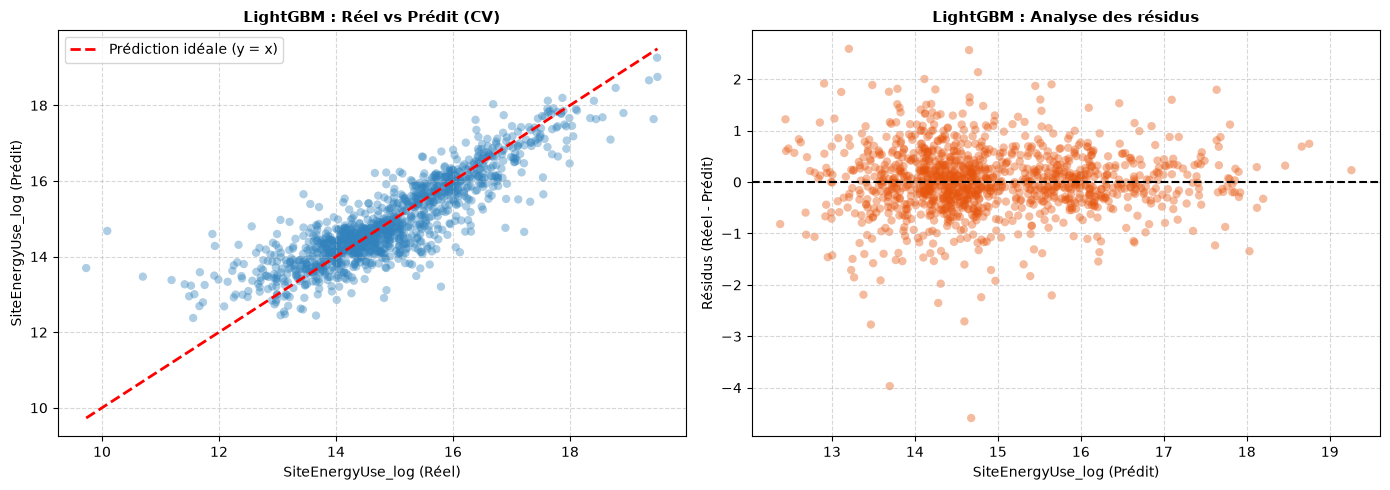

In [39]:
# Etape 2 : Auditer le modèle vainqueur (Light LGBM) avec cross_val_predict pour analyser la présence d'erreurs SUR ENERGY

# Modèle issu de la pré-optimisation manuelle
lgb_model = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.032, max_depth=4, subsample=0.76, random_state=42, num_leaves=16, min_child_samples=4, subsample_freq=1, verbose=-1, n_jobs=-1)

# Pipeline hermétique sans fuite de données
pipe_lgb_audit = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', lgb_model)
])

# Prédictions out-of-fold sur le Train brut
y_pred_cv_lgb = cross_val_predict(pipe_lgb_audit, X_train, y_train_energy, cv=cv, n_jobs=-1)
residuals_lgb = y_train_energy - y_pred_cv_lgb

# Tracé des graphiques de diagnostic
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graphe 1 : Réel vs Prédit
axes[0].scatter(y_train_energy, y_pred_cv_lgb, alpha=0.4, color='#3182bd', edgecolors='none')
min_val = min(y_train_energy.min(), y_pred_cv_lgb.min())
max_val = max(y_train_energy.max(), y_pred_cv_lgb.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Prédiction idéale (y = x)')
axes[0].set_title("LightGBM : Réel vs Prédit (CV)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("SiteEnergyUse_log (Réel)")
axes[0].set_ylabel("SiteEnergyUse_log (Prédit)")
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Graphe 2 : Résidus vs Prédit (Homoscédasticité et biais)
axes[1].scatter(y_pred_cv_lgb, residuals_lgb, alpha=0.4, color='#e6550d', edgecolors='none')
axes[1].axhline(0, color='black', linestyle='--', lw=1.5)
axes[1].set_title("LightGBM : Analyse des résidus", fontsize=11, fontweight='bold')
axes[1].set_xlabel("SiteEnergyUse_log (Prédit)")
axes[1].set_ylabel("Résidus (Réel - Prédit)")
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

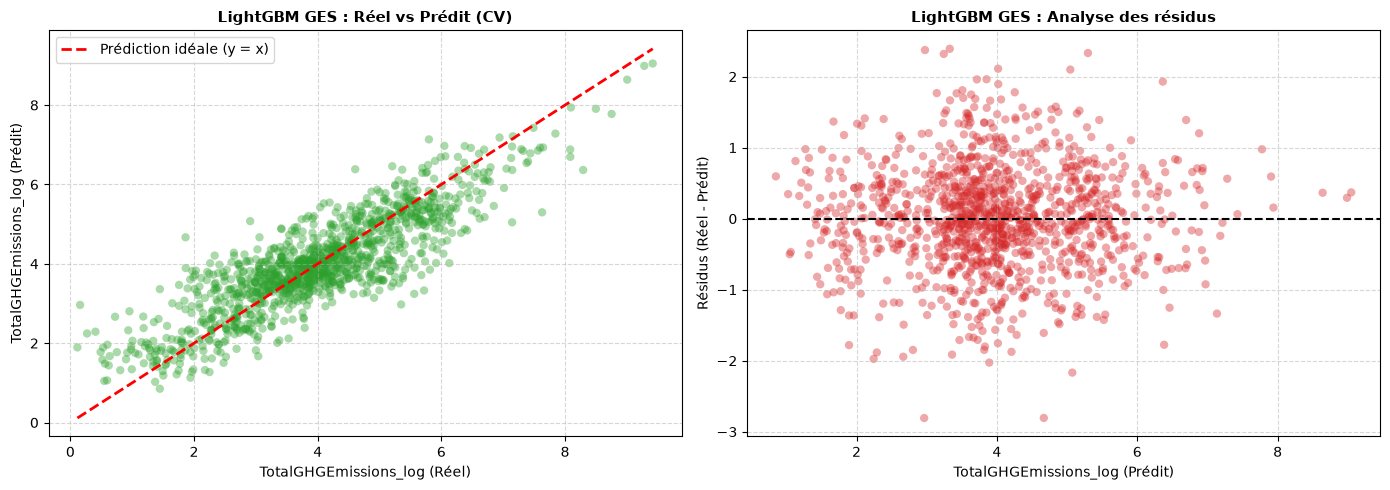

In [40]:
# Etape 2 bis : Auditer le modèle vainqueur (Light LGBM) avec cross_val_predict pour analyser la présence d'erreurs SUR GHG

# Modèle issu de la pré-optimisation manuelle
lgbm_model_ghg = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.035, max_depth=4, subsample=0.75, random_state=42, num_leaves=15, min_child_samples=4, subsample_freq=1, verbose=-1, n_jobs=-1)

# Pipeline hermétique sans fuite de données
pipe_lgb_audit_ghg = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', lgbm_model_ghg)
])

# Prédictions out-of-fold sur le Train brut
y_pred_cv_lgbm_ghg = cross_val_predict(pipe_lgb_audit_ghg, X_train, y_train_ghg, cv=cv, n_jobs=-1)
residuals_ghg = y_train_ghg - y_pred_cv_lgbm_ghg

# Tracé des graphiques de diagnostic
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graphe 1 : Valeurs réelles vs Prédictions
axes[0].scatter(y_train_ghg, y_pred_cv_lgbm_ghg, alpha=0.4, color='#2ca02c', edgecolors='none')
min_val = min(y_train_ghg.min(), y_pred_cv_lgbm_ghg.min())
max_val = max(y_train_ghg.max(), y_pred_cv_lgbm_ghg.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Prédiction idéale (y = x)')
axes[0].set_title("LightGBM GES : Réel vs Prédit (CV)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("TotalGHGEmissions_log (Réel)")
axes[0].set_ylabel("TotalGHGEmissions_log (Prédit)")
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Graphe 2 : Analyse des résidus
axes[1].scatter(y_pred_cv_lgbm_ghg, residuals_ghg, alpha=0.4, color='#d62728', edgecolors='none')
axes[1].axhline(0, color='black', linestyle='--', lw=1.5)
axes[1].set_title("LightGBM GES : Analyse des résidus", fontsize=11, fontweight='bold')
axes[1].set_xlabel("TotalGHGEmissions_log (Prédit)")
axes[1].set_ylabel("Résidus (Réel - Prédit)")
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [41]:
# code pour extraire les bâtiments dont l'erreur absolue dépasse 2 fois l'écart type (les 5% les plus mal prédits) et observer leurs caractéristiques
# SUR ENERGY

# Calcul du seuil statistique d'erreur (2 écarts-types des résidus)
std_residuals_lgbm = np.std(residuals_lgb)
outlier_threshold_lgbm = 2 * std_residuals_lgbm

# Construction du DataFrame d'audit aligné sur l'index de X_train
df_audit_lgbm = X_train.copy()
df_audit_lgbm['Reel_log'] = y_train_energy
df_audit_lgbm['Predit_log'] = y_pred_cv_lgb
df_audit_lgbm['Residu'] = residuals_lgb
df_audit_lgbm['Erreur_Absolue'] = np.abs(residuals_lgb)
df_audit_lgbm['Ratio_Reel_sur_Predit'] = np.exp(residuals_lgb) # Ratio multiplicatif sur l'échelle réelle : exp(Reel - Predit) = Réel / Prédit

# Filtrage des bâtiments atypiques (> 2 sigmas)
outliers_lgbm = df_audit_lgbm[df_audit_lgbm['Erreur_Absolue'] > outlier_threshold_lgbm].sort_values(
    by='Erreur_Absolue', ascending=False
)

print(f"Nombre total de bâtiments analysés : {len(df_audit_lgbm)}")
print(f"Bâtiments atypiques détectés (> 2σ) : {len(outliers_lgbm)} ({len(outliers_lgbm)/len(df_audit_lgbm)*100:.1f}%)")

# Sélection dynamique des colonnes informatives présentes
candidate_cols = [
    'PrimaryPropertyType', 'Neighborhood', 'PropertyGFATotal', 
    'BuildingAge', 'NumberofFloors', 'HasGas', 'HasSteam',
    'Ratio_Reel_sur_Predit', 'Residu', 'Reel_log', 'Predit_log'
]
cols_to_display = [col for col in candidate_cols if col in df_audit_lgbm.columns]

# Affichage des 5 pires prédictions
outliers_lgbm[cols_to_display].head(5).round(2)

Nombre total de bâtiments analysés : 1188
Bâtiments atypiques détectés (> 2σ) : 69 (5.8%)


,PrimaryPropertyType,Neighborhood,BuildingAge,NumberofFloors,HasGas,HasSteam,Ratio_Reel_sur_Predit,Residu,Reel_log,Predit_log
1229,Small- and Mid-Sized Office,DOWNTOWN,113,3,0,0,0.01,-4.59,10.09,14.68
2189,Other,GREATER DUWAMISH,106,3,0,0,0.02,-3.97,9.73,13.70
1295,Other,DOWNTOWN,116,3,0,0,0.06,-2.77,10.70,13.47
1045,Retail Store,GREATER DUWAMISH,63,1,1,0,0.07,-2.71,11.89,14.60
1593,Other,BALLARD,116,3,1,0,13.34,2.59,15.80,13.20


In [42]:
# code pour extraire les bâtiments dont l'erreur absolue dépasse 2 fois l'écart type (les 5% les plus mal prédits) et observer leurs caractéristiques
# SUR GHG

# Extraction des pires prédictions (> 2 écarts-types)
std_residuals_ghg = np.std(residuals_ghg)
threshold_ghg = 2 * std_residuals_ghg

df_audit_ghg = X_train.copy()
df_audit_ghg['Reel_log'] = y_train_ghg
df_audit_ghg['Predit_log'] = y_pred_cv_lgbm_ghg
df_audit_ghg['Residu'] = residuals_ghg
df_audit_ghg['Erreur_Absolue'] = np.abs(residuals_ghg)
df_audit_ghg['Ratio_Reel_sur_Predit'] = np.exp(residuals_ghg)

outliers_ghg = df_audit_ghg[df_audit_ghg['Erreur_Absolue'] > threshold_ghg].sort_values(
    by='Erreur_Absolue', ascending=False
)

print(f"Bâtiments atypiques GES détectés (> 2σ) : {len(outliers_ghg)} ({len(outliers_ghg)/len(df_audit_ghg)*100:.1f}%)")

candidate_cols = [
    'PrimaryPropertyType', 'Neighborhood', 'PropertyGFATotal', 
    'NumberofFloors', 'HasGas', 'HasSteam', 'BuildingAge',
    'Ratio_Reel_sur_Predit', 'Residu', 'Reel_log', 'Predit_log'
]
cols_to_display = [col for col in candidate_cols if col in df_audit_ghg.columns]

outliers_ghg[cols_to_display].head(5).round(2)


Bâtiments atypiques GES détectés (> 2σ) : 64 (5.4%)


,PrimaryPropertyType,Neighborhood,NumberofFloors,HasGas,HasSteam,BuildingAge,Ratio_Reel_sur_Predit,Residu,Reel_log,Predit_log
1229,Small- and Mid-Sized Office,DOWNTOWN,3,0,0,113,0.06,-2.81,0.16,2.96
316,Distribution Center,GREATER DUWAMISH,1,1,0,56,0.06,-2.81,1.86,4.67
1593,Other,BALLARD,3,1,0,116,10.93,2.39,5.72,3.33
240,Other,NORTHEAST,5,0,0,47,10.74,2.37,5.35,2.98
119,Other,DOWNTOWN,11,1,0,12,10.30,2.33,7.63,5.30


### Analyse des résultats de l'audit 

On remarque pour l'energie et les GHG une sur estimation sur les plus faibles valeurs et une sous estimation sur les valeurs les plus importantes (on va avoir un modèle optimiste)

On remarque le batiment 1229 qui ressort en anomalie dans les 2 cibles également 3 sur 5 des other sous entendant des batiments plus inhabituels donc moins appris et compris par le modèle

On se confirme avec les résidus que la taille est très influente dans l'augmentation de l'energie
et que d'autre variables influence de manière non négligeable les GHG : le type d'energie (gas et steam) ou l'activité en plus de la taille

<div style="border: 1px solid RGB(36,172,189);" >
<h3 style="margin: auto; padding: 20px; color: RGB(36,172,189); ">Optimisation et interprétation du modèle</h3>
</div>

A réaliser :
* Reprennez le meilleur algorithme que vous avez sécurisé via l'étape précédente, et réalisez une GridSearch de petite taille sur au moins 3 hyperparamètres.
* Si le meilleur modèle fait partie de la famille des modèles à arbres (RandomForest, GradientBoosting) alors utilisez la fonctionnalité feature importance pour identifier les features les plus impactantes sur la performance du modèle. Sinon, utilisez la méthode Permutation Importance de sklearn.

In [43]:
# Recherche des paramètres optimaux POUR ENERGY

# Configuration de la validation croisée
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Modèle de base LightGBM
lgbm_base = lgb.LGBMRegressor(max_depth=4, subsample=0.76, subsample_freq=1, random_state=42, verbose=-1, n_jobs=-1)

# Assemblage dans le Pipeline anti-fuite
pipeline_lgb_energy = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', lgbm_base)
])

# Grille d'hyperparamètres ciblée autour de mes paramètres empiriques
param_grid_lgb = {
    'regressor__num_leaves': [14, 15, 16],
    'regressor__min_child_samples': [3, 4, 5],
    'regressor__learning_rate': [0.028, 0.03, 0.032],
    'regressor__n_estimators': [320, 340, 360]
}

# Exécution du GridSearch
grid_search_lgb = GridSearchCV(
    estimator=pipeline_lgb_energy,
    param_grid=param_grid_lgb,
    cv=cv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    return_train_score=True
)

# Fit strict sur X_train brut (le préprocessing est recalculé à chaque pli)
grid_search_lgb.fit(X_train, y_train_energy)

# Affichage des meilleurs réglages et conversion de la MAE en valeur positive

print(f"Meilleurs hyperparamètres (Energie) : {grid_search_lgb.best_params_}")
print(f"Meilleure MAE Val (CV) moyenne (log) : {-grid_search_lgb.best_score_:.3f}")

Meilleurs hyperparamètres (Energie) : {'regressor__learning_rate': 0.03, 'regressor__min_child_samples': 4, 'regressor__n_estimators': 340, 'regressor__num_leaves': 15}
Meilleure MAE Val (CV) moyenne (log) : 0.467


In [44]:
# Modèle vainqueur issu du GridSearch Energy
best_lgb = grid_search_lgb.best_estimator_

# Prédictions hors-échantillon globales via cross_val_predict sur X_train brut
y_pred_log_lgb = cross_val_predict(best_lgb, X_train, y_train_energy, cv=cv, n_jobs=-1)

# Reconversion vers les unités réelles (kBtu) avec borne physique à 0
y_pred_real_lgb = np.clip(np.expm1(y_pred_log_lgb), 0, None)
y_train_energy_real = np.expm1(y_train_energy)

# Tableau récapitulatif aligné sur les métriques de predict
res_best_lgb = pd.DataFrame([{
    'Modèle': 'LightGBM Optimisé (GridSearch)',
    'R² (log)': r2_score(y_train_energy, y_pred_log_lgb),
    'MAE (log)': mean_absolute_error(y_train_energy, y_pred_log_lgb),
    'RMSE (log)': np.sqrt(mean_squared_error(y_train_energy, y_pred_log_lgb)),
    'MAE Réelle (kBtu)': mean_absolute_error(y_train_energy_real, y_pred_real_lgb)
}])

res_best_lgb.round(3)

,Modèle,R² (log),MAE (log),RMSE (log),MAE Réelle (kBtu)
0,LightGBM Optimisé (GridSearch),0.758,0.467,0.651,3278076.898


Par défaut, LightGBM quantifie l'importance par la fréquence de découpe (Split), ce qui surévalue les variables continues comme l'âge du bâtiment. Nous avons basculé sur le Gain pour trouver la vraie réduction d'impureté


Top 10 des variables les plus importantes pour l'Énergie (Gain MDI) :
                                        Feature  Importance (%)
                           PropertyGFATotal_log           67.40
                                    BuildingAge            5.49
                  PrimaryPropertyType_Warehouse            4.39
PrimaryPropertyType_Supermarket / Grocery Store            3.72
                                         HasGas            3.46
                      PrimaryPropertyType_Other            2.28
                                 NumberofFloors            2.17
      PrimaryPropertyType_Self-Storage Facility            1.87
        PrimaryPropertyType_Distribution Center            1.48
                 PrimaryPropertyType_Laboratory            1.20


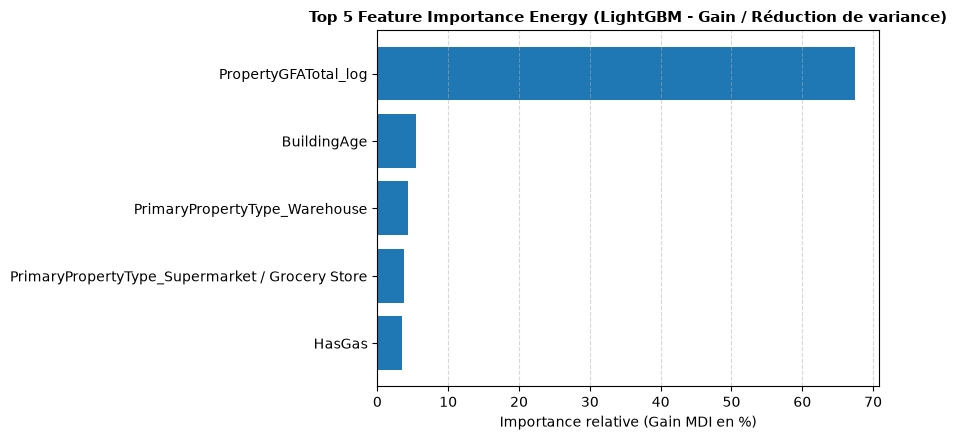

In [45]:
# Recherche des variables les plus importantes (Feature Importance) POUR ENERGY

# Accès au modèle LightGBM et au préprocesseur fitté dans le Pipeline
lgb_regressor = best_lgb.named_steps['regressor']
preprocessor_fitted = best_lgb.named_steps['preprocessor']

# Extraction de l'importance par GAIN (réduction réelle de variance MDI)
importances_gain_energy = lgb_regressor.booster_.feature_importance(importance_type='gain')
feature_names = preprocessor_fitted.get_feature_names_out()

# Normalisation en pourcentage (somme = 100 %)
importances_gain_pct_energy = (
    importances_gain_energy / importances_gain_energy.sum()
) * 100

df_importance_energy = pd.DataFrame({
    'Feature': feature_names,
    'Importance (%)': importances_gain_pct_energy
}).sort_values(by='Importance (%)', ascending=False)

# Affichage des 10 variables les plus impactantes
print("\nTop 10 des variables les plus importantes pour l'Énergie (Gain MDI) :")
print(df_importance_energy.head(10).round(2).to_string(index=False))

# Tracé graphique horizontal des 5 variables maîtresses
top_n = 5
top_features_energy = df_importance_energy.head(top_n).sort_values(
    by='Importance (%)', ascending=True
)

plt.figure(figsize=(9, 4.5))
plt.barh(
    top_features_energy['Feature'],
    top_features_energy['Importance (%)'],
    color='#1f77b4',
    edgecolor='none'
)
plt.title(
    f"Top {top_n} Feature Importance Energy (LightGBM - Gain / Réduction de variance)",
    fontsize=11,
    fontweight='bold'
)
plt.xlabel("Importance relative (Gain MDI en %)")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [46]:
# Recherche des paramètres optimaux POUR GHG

# Configuration du modèle et de la validation croisée
cv = KFold(n_splits=5, shuffle=True, random_state=42)
lgbm_base_ghg = lgb.LGBMRegressor(max_depth=4, subsample=0.75, subsample_freq=1, random_state=42, verbose=-1, n_jobs=-1)

# Assemblage hermétique dans le Pipeline
pipeline_lgb_ghg = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', lgbm_base_ghg)
])

# Grille d'hyperparamètres ciblant strictement l'étape 'regressor'
param_grid_ghg = {
    'regressor__num_leaves': [14, 15, 16],
    'regressor__min_child_samples': [3, 4, 5],
    'regressor__learning_rate': [0.0355, 0.0360, 0.0365],
    'regressor__n_estimators': [270, 275, 280]
}

# Exécution du GridSearchCV sur les GES
grid_search_ghg = GridSearchCV(
    estimator=pipeline_lgb_ghg,
    param_grid=param_grid_ghg,
    cv=cv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    return_train_score=True
)

# Fit strict sur X_train brut (préprocessing recalculé à chaque pli)
grid_search_ghg.fit(X_train, y_train_ghg)

# Modèle vainqueur (Pipeline complet) et meilleurs scores
best_lgbm_ghg = grid_search_ghg.best_estimator_
print(f"Meilleurs hyperparamètres (GES) : {grid_search_ghg.best_params_}")
print(f"Meilleure MAE Val (CV) moyenne (log) : {-grid_search_ghg.best_score_:.3f}")

Meilleurs hyperparamètres (GES) : {'regressor__learning_rate': 0.036, 'regressor__min_child_samples': 4, 'regressor__n_estimators': 275, 'regressor__num_leaves': 15}
Meilleure MAE Val (CV) moyenne (log) : 0.561


In [47]:
# Modèle vainqueur issu du GridSearch GHG
best_lgbm_ghg = grid_search_ghg.best_estimator_

# Prédictions hors-échantillon globales via cross_val_predict sur X_train brut
y_pred_log_lgb_ghg = cross_val_predict(best_lgbm_ghg, X_train, y_train_ghg, cv=cv, n_jobs=-1)

# Reconversion vers les unités réelles (kBtu)
y_pred_real_lgb_ghg = np.clip(np.expm1(y_pred_log_lgb_ghg), 0, None)
y_train_ghg_real = np.expm1(y_train_ghg)

# Tableau récapitulatif aligné sur les métriques de predict
res_best_lgb_ghg = pd.DataFrame([{
    'Modèle': 'LightGBM Optimisé GHG (GridSearch)',
    'R² (log)': r2_score(y_train_ghg, y_pred_log_lgb_ghg),
    'MAE (log)': mean_absolute_error(y_train_ghg, y_pred_log_lgb_ghg),
    'RMSE (log)': np.sqrt(mean_squared_error(y_train_ghg, y_pred_log_lgb_ghg)),
    'MAE Réelle (kBtu)': mean_absolute_error(y_train_ghg_real, y_pred_real_lgb_ghg)
}])

res_best_lgb_ghg.round(3)

,Modèle,R² (log),MAE (log),RMSE (log),MAE Réelle (kBtu)
0,LightGBM Optimisé GHG (GridSearch),0.743,0.561,0.73,85.119



Top 10 des variables par GAIN (MDI réel - GES) :
                                        Feature  Importance (%)
                           PropertyGFATotal_log           46.23
                                         HasGas           21.29
                                    BuildingAge            5.04
                                       HasSteam            4.60
                  PrimaryPropertyType_Warehouse            3.07
PrimaryPropertyType_Supermarket / Grocery Store            2.56
                                 NumberofFloors            2.32
                   PrimaryPropertyType_Hospital            2.10
                      PrimaryPropertyType_Other            1.96
                 PrimaryPropertyType_Laboratory            1.42


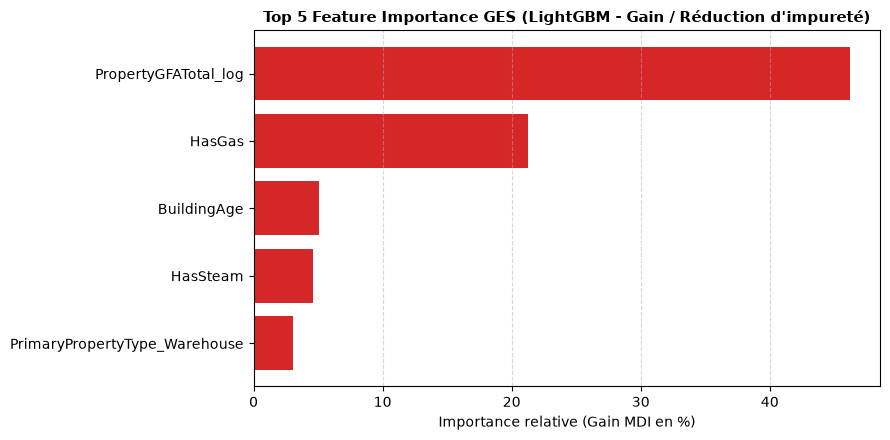

In [48]:
# Recherche des variables les plus importantes (Feature Importance) POUR GHG

# Interprétation via la Feature Importance
# Extraction du regressor et du preprocessor optimisé dans le Pipeline
lgb_regressor_ghg = best_lgbm_ghg.named_steps['regressor']
preprocessor_fitted_ghg = best_lgbm_ghg.named_steps['preprocessor']

# Extraction de l'importance par GAIN (réduction de variance MDI) et des noms réels de colonnes
importances_gain_ghg = lgb_regressor_ghg.booster_.feature_importance(importance_type='gain')
feature_names_ghg = preprocessor_fitted_ghg.get_feature_names_out()

# Normalisation en pourcentage (somme = 100 %) comme dans Scikit-Learn
importances_gain_pct_ghg = (importances_gain_ghg / importances_gain_ghg.sum()) * 100

df_importance_ghg = pd.DataFrame({
    'Feature': feature_names_ghg,
    'Importance (%)': importances_gain_pct_ghg
}).sort_values(by='Importance (%)', ascending=False)

print("\nTop 10 des variables par GAIN (MDI réel - GES) :")
print(df_importance_ghg.head(10).round(2).to_string(index=False))

# 4. Tracé horizontal des 5 variables maîtresses
top_n = 5
top_features_ghg = df_importance_ghg.head(top_n).sort_values(
    by='Importance (%)', ascending=True
)

plt.figure(figsize=(9, 4.5))
plt.barh(
    top_features_ghg['Feature'],
    top_features_ghg['Importance (%)'],
    color='#d62728',
    edgecolor='none'
)
plt.title(
    f"Top {top_n} Feature Importance GES (LightGBM - Gain / Réduction d'impureté)",
    fontsize=11,
    fontweight='bold'
)
plt.xlabel("Importance relative (Gain MDI en %)")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

<div style="border: 1px solid RGB(36,172,189);" >
<h3 style="margin: auto; padding: 20px; color: RGB(36,172,189); ">Evaluation finale sur le jeu de test (X_test)</h3>
</div>

In [49]:
# Evaluation finale sur le jeu de test (X_test, y_test) pour Energy et GHG

# Cibles réelles non logarithmiques du jeu de test
y_test_energy_real = np.expm1(y_test_energy)
y_test_ghg_real = np.expm1(y_test_ghg)

# Calcul des cibles réelles d'entraînement pour évaluer la MAE réelle de validation
y_train_energy_real = np.expm1(y_train_energy)
y_train_ghg_real = np.expm1(y_train_ghg)

# Prédictions hors-échantillon de VALIDATION (CV sur X_train brut)
# Calcul des prédictions out-of-fold pour obtenir les métriques de validation
y_val_pred_energy_log = cross_val_predict(best_lgb, X_train, y_train_energy, cv=cv, n_jobs=-1)
y_val_pred_ghg_log = cross_val_predict(best_lgbm_ghg, X_train, y_train_ghg, cv=cv, n_jobs=-1)

# Prédictions directes via les Pipelines optimisés (préprocessing automatique), lors de l'enregistrement du pipeline GridSearchCV on a fait un fit sur xtrain original
y_test_pred_energy_log = best_lgb.predict(X_test)
y_test_pred_ghg_log = best_lgbm_ghg.predict(X_test)

# Reconversion à l'échelle physique avec seuil inférieur à zéro
y_test_pred_energy_real = np.clip(np.expm1(y_test_pred_energy_log), 0, None)
y_test_pred_ghg_real = np.clip(np.expm1(y_test_pred_ghg_log), 0, None)

# Reconversion des prédictions de validation vers les unités physiques
y_val_pred_energy_real = np.clip(np.expm1(y_val_pred_energy_log), 0, None)
y_val_pred_ghg_real = np.clip(np.expm1(y_val_pred_ghg_log), 0, None)

# Synthèse comparative : Métriques de Validation (CV) vs Test Final
# Intégration complète des métriques demandées (R², MAE, RMSE en Validation CV et Test)
final_test_results = pd.DataFrame([
    {
        'Cible': 'Consommation Énergie (SiteEnergyUse)',
        'R² Val (CV)': r2_score(y_train_energy, y_val_pred_energy_log),
        'R² Test Final': r2_score(y_test_energy, y_test_pred_energy_log),
        'MAE Val (log)': mean_absolute_error(y_train_energy, y_val_pred_energy_log),
        'MAE Test (log)': mean_absolute_error(y_test_energy, y_test_pred_energy_log),
        'RMSE Val (log)': np.sqrt(mean_squared_error(y_train_energy, y_val_pred_energy_log)),
        'RMSE Test (log)': np.sqrt(mean_squared_error(y_test_energy, y_test_pred_energy_log)),
        'MAE Réelle Val': mean_absolute_error(y_train_energy_real, y_val_pred_energy_real),
        'MAE Réelle Test': mean_absolute_error(y_test_energy_real, y_test_pred_energy_real),
        'Unité Réelle': 'kBtu'
    },
    {
        'Cible': 'Émissions GES (TotalGHGEmissions)',
        'R² Val (CV)': r2_score(y_train_ghg, y_val_pred_ghg_log),
        'R² Test Final': r2_score(y_test_ghg, y_test_pred_ghg_log),
        'MAE Val (log)': mean_absolute_error(y_train_ghg, y_val_pred_ghg_log),
        'MAE Test (log)': mean_absolute_error(y_test_ghg, y_test_pred_ghg_log),
        'RMSE Val (log)': np.sqrt(mean_squared_error(y_train_ghg, y_val_pred_ghg_log)),
        'RMSE Test (log)': np.sqrt(mean_squared_error(y_test_ghg, y_test_pred_ghg_log)),
        'MAE Réelle Val': mean_absolute_error(y_train_ghg_real, y_val_pred_ghg_real),
        'MAE Réelle Test': mean_absolute_error(y_test_ghg_real, y_test_pred_ghg_real),
        'Unité Réelle': 'Tonnes CO2'
    }
])

display(final_test_results.round(3))

,Cible,R² Val (CV),R² Test Final,MAE Val (log),MAE Test (log),RMSE Val (log),RMSE Test (log),MAE Réelle Val,MAE Réelle Test,Unité Réelle
0,Consommation Énergie (SiteEnergyUse),0.758,0.668,0.467,0.552,0.651,0.762,3278076.898,5617366.564,kBtu
1,Émissions GES (TotalGHGEmissions),0.743,0.675,0.561,0.625,0.730,0.823,85.119,111.979,Tonnes CO2


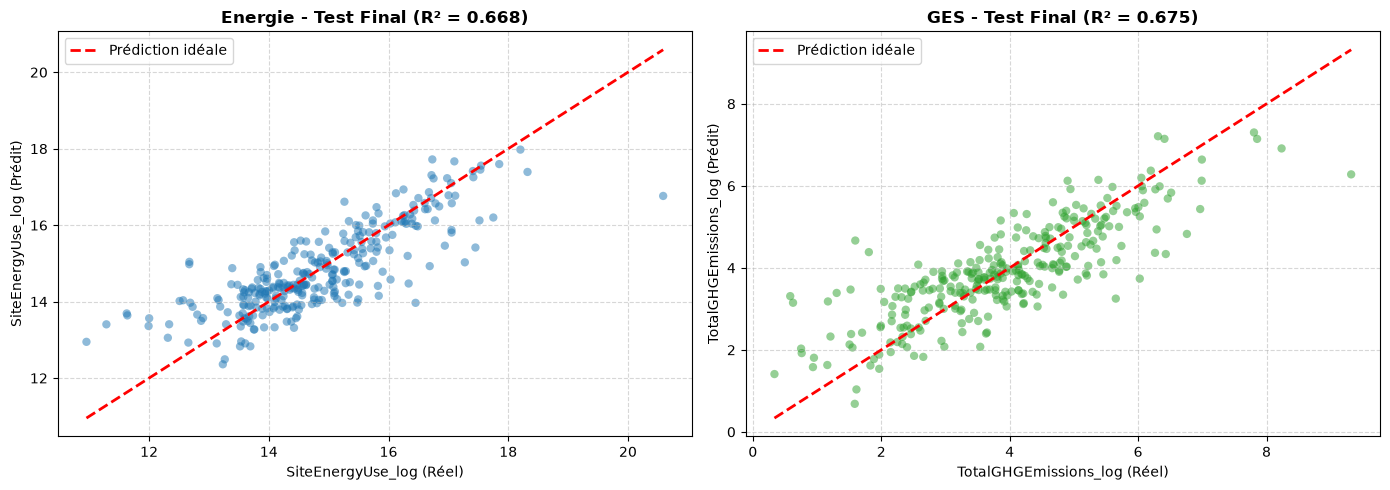

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graphe Energie sur Test
axes[0].scatter(y_test_energy, y_test_pred_energy_log, alpha=0.5, color='#1f77b4', edgecolors='none')
min_e = min(y_test_energy.min(), y_test_pred_energy_log.min())
max_e = max(y_test_energy.max(), y_test_pred_energy_log.max())
axes[0].plot([min_e, max_e], [min_e, max_e], 'r--', lw=2, label='Prédiction idéale')
axes[0].set_title(f"Energie - Test Final (R² = {r2_score(y_test_energy, y_test_pred_energy_log):.3f})", fontweight='bold')
axes[0].set_xlabel("SiteEnergyUse_log (Réel)")
axes[0].set_ylabel("SiteEnergyUse_log (Prédit)")
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Graphe GES sur Test
axes[1].scatter(y_test_ghg, y_test_pred_ghg_log, alpha=0.5, color='#2ca02c', edgecolors='none')
min_g = min(y_test_ghg.min(), y_test_pred_ghg_log.min())
max_g = max(y_test_ghg.max(), y_test_pred_ghg_log.max())
axes[1].plot([min_g, max_g], [min_g, max_g], 'r--', lw=2, label='Prédiction idéale')
axes[1].set_title(f"GES - Test Final (R² = {r2_score(y_test_ghg, y_test_pred_ghg_log):.3f})", fontweight='bold')
axes[1].set_xlabel("TotalGHGEmissions_log (Réel)")
axes[1].set_ylabel("TotalGHGEmissions_log (Prédit)")
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()